<center>
    <img src="https://rockborne.com/wp-content/uploads/2021/07/LandingPage-Header-RED-CENTRE.jpg" width="900" alt="Rockborne logo" />
</center>

# Automated Exploratory Data Analysis with Sweetviz

## Overview

In the previous EDA lecture we worked through the manual logic of exploratory analysis: inspect the data, check quality, summarise variables, compare groups, build charts, and turn the evidence into conclusions.

This notebook keeps that same workflow, but adds **Sweetviz** as an automated EDA tool.

Sweetviz is useful because it gives us a quick first profile of a dataset. It can show column types, missing values, distributions, associations and useful comparisons. It does not replace the analyst. It gives the analyst a faster starting point.

## Learning objectives

By the end of this notebook you will be able to:

- Explain where automated EDA fits in the normal analysis workflow.
- Install and import Sweetviz in Databricks.
- Load data with pandas using the links in `config.py`.
- Build a simple Sweetviz report with `sv.analyze()`.
- Build a target-focused Sweetviz report when there is a clear outcome field.
- Read a Sweetviz report in a structured way.
- Use pandas tables and charts to follow up on what the report highlights.
- Complete a live Superstore EDA lab with coached solution walkthroughs.

## Prerequisites

You should already be comfortable with:

- Basic pandas inspection methods such as `.head()`, `.shape`, `.info()`, `.describe()` and `.value_counts()`.
- Selecting and filtering columns.
- Creating new columns.
- Grouping and aggregating with `.groupby()`.
- Creating simple Matplotlib or Seaborn charts.
- Explaining what a table or chart means in plain English.

## Index

- [Section 0: Setup](#setup)
- [Section 1: Why automated EDA?](#why)
- [Section 2: Load data with pandas from config.py](#load)
- [Section 3: First inspection](#first)
- [Section 4: Titanic walkthrough](#titanic)
- [Section 5: Reading a Sweetviz report](#reading)
- [Section 6: Superstore live class lab](#superstore-lab)
- [Section 7: Next steps after automated EDA](#next-steps)
- [Section 8: Wrap up and further exploration](#wrapup)

<a id="setup"></a>
# Section 0: Setup

Sweetviz is the only extra library installed in this notebook.

Run the install cell before importing Sweetviz. If Sweetviz has already been imported in the current session with another version, restart the Python session once, then run the notebook from the top.

In [0]:
%pip install sweetviz==2.3.1

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


## Import libraries

We keep the imports in one place so we can see the tools used in the notebook.

In [0]:
# pandas is used for data inspection and follow up analysis.
# Matplotlib and Seaborn are used for supporting charts.
# Sweetviz is used for automated EDA reports.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sweetviz as sv

In [0]:
# The file in Databricks should be named config.py.
# It sits in the same folder as this notebook.
# session_datasets contains the HTTPS links to the datasets used in the session.

from config import session_datasets

In [0]:
# Check the dataset names available from config.py.
# This is a quick confidence check before reading any data.

session_datasets.keys()

dict_keys(['Production.Product', 'Salaries', 'train_titanic', 'superstore'])

<a id="why"></a>
# Section 1: Why automated EDA?

Exploratory Data Analysis is an investigation. It helps us understand what is in the data before we build a model, dashboard or recommendation.

A normal EDA workflow asks:

- What is the shape of the data?
- What does each column mean?
- Which fields are numeric, categorical or date-like?
- Where are values missing?
- Are any values implausible?
- Which groups behave differently?
- Which findings need manual follow up?

Sweetviz helps with the first pass. It does not decide which findings matter. That is still the analyst's job.

## The pattern we will use

The notebook uses the same pattern repeatedly:

1. Load the data.
2. Inspect it manually.
3. Prepare only what is needed.
4. Run Sweetviz.
5. Read the report.
6. Follow up with pandas.
7. Explain the finding in plain English.

This is important for beginners because it prevents Sweetviz from becoming a button we press without understanding the output.

<a id="load"></a>
# Section 2: Load data with pandas from config.py

The data is stored in an S3 bucket and shared through HTTPS links.

We read the CSV files directly with `pd.read_csv()`. Sweetviz works with pandas DataFrames, so no conversion step is needed.

In [0]:
# We store the Titanic link in a clear variable.
# This keeps the next read cell short and easy to understand

titanic_path = session_datasets["train_titanic"]

In [0]:
# Print the Titanic path in this cell.

print(titanic_path)

s3a://rockborne-bucket-01-cbs/Data_Sources_CBS_Risk/train_titanic.csv


In [0]:
# Read Titanic directly with pandas.
# pandas uses the first row as column names and infers basic data types.

titanic_raw = pd.read_csv(titanic_path)

In [0]:
# Confirm that Titanic loaded.
# Shape returns rows first, columns second.

print("Titanic data loaded")
print(titanic_raw.shape)

Titanic data loaded
(891, 12)


In [0]:
# Store the Superstore link in its own variable.
# We use this later for the class exercises.

superstore_path = session_datasets["superstore"]

In [0]:
# Print the Superstore path in this cell.
# This keeps the data loading checks separated.

print(superstore_path)

s3a://rockborne-bucket-01-cbs/Data_Sources_CBS_Risk/superstore.csv


In [0]:
# Read Superstore directly with pandas.
# This file is not UTF-8 encoded, so we pass encoding="latin1".

store_raw = pd.read_csv(superstore_path, encoding="latin1")

In [0]:
# Confirm that Superstore loaded.
# We do this separately from Titanic so each output is easy to read.

print("Superstore data loaded")
print(store_raw.shape)

Superstore data loaded
(9994, 21)


<a id="first"></a>
# Section 3: First inspection

Before using Sweetviz, we still inspect the raw data manually.

This confirms that the data loaded correctly and gives us a first look at the columns.

In [0]:
# Look at the first few Titanic rows.
# This is a quick check of column names and example values.

titanic_raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,None,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,None,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,None,S


In [0]:
# Look at the first few Superstore rows.

store_raw.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164


In [0]:
# List the Titanic columns.
# Column names matter because we will reference them directly in pandas.

titanic_raw.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [0]:
# List the Superstore columns.
# This helps learners recognise the business fields before the lab.

store_raw.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [0]:
# Check Titanic data types.
# This tells us whether pandas inferred numbers and text correctly.

titanic_raw.dtypes

PassengerId      int32
Survived         int32
Pclass           int32
Name            object
Sex             object
Age            float64
SibSp            int32
Parch            int32
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [0]:
# Check Superstore data types.
# Dates often need extra attention after CSV loading.

store_raw.dtypes

Row ID             int32
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int32
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales             object
Quantity          object
Discount          object
Profit           float64
dtype: object

### Quick check: two minutes

Use the raw DataFrames to answer these questions:

1. How many rows are in Titanic?
2. How many rows are in Superstore?
3. Which Titanic columns have missing values?
4. Which Superstore columns look like date fields?

In [0]:
# Your turn.
# Hint 1: use .shape for rows and columns.
# Hint 2: use .isna().sum() for missing values.
# Hint 3: use .columns to look through field names.

In [0]:
# Coach answer.
# This keeps the check short and factual.

print("Titanic shape:", titanic_raw.shape)
print("Superstore shape:", store_raw.shape)

Titanic shape: (891, 12)
Superstore shape: (9994, 21)


In [0]:
# Coach answer.
# Sort missing values so the most incomplete columns are shown first.

titanic_raw.isna().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

In [0]:
# Coach answer.
# This is a simple way to spot date-like column names.

[column for column in store_raw.columns if "Date" in column]

['Order Date', 'Ship Date']

<a id="titanic"></a>
# Section 4: Titanic walkthrough

Titanic is used first because the dataset is small and has a clear outcome column.

The aim is to teach the Sweetviz workflow before moving to the larger Superstore lab.

## Step 1: copy the raw data

We copy the raw DataFrame before changing anything.

This is a good habit because it preserves the original data loaded from S3.

In [0]:
# Work on a copy.
# The original titanic_raw DataFrame remains unchanged.

titanic = titanic_raw.copy()

## Step 2: standardise column names

Standardised column names make code easier to write and read.

For this notebook we use lowercase names and replace spaces with underscores.

In [0]:
# Clean column names in one step.
# This avoids repeated typing of mixed-case column names.

titanic.columns = titanic.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)

In [0]:
# Check that the column names changed as expected.
# This is a small but important validation step.

titanic.columns.tolist()

['passengerid',
 'survived',
 'pclass',
 'name',
 'sex',
 'age',
 'sibsp',
 'parch',
 'ticket',
 'fare',
 'cabin',
 'embarked']

## Step 3: confirm the inferred data types

pandas inferred the data types when it read the CSV file. This means the main numeric columns should already be numeric.

We check the data types before changing anything. We only convert a column when the inspection shows that its current type is wrong.

In [0]:
# Check the data types inferred by pandas.
# Survived, Pclass, Age and Fare should already be numeric.

titanic.dtypes

passengerid      int32
survived         int32
pclass           int32
name            object
sex             object
age            float64
sibsp            int32
parch            int32
ticket          object
fare           float64
cabin           object
embarked        object
dtype: object

## Step 4: build a simple Sweetviz report

We begin with the basic Sweetviz pattern.

There is no target column and no feature engineering at this stage. The purpose is to see what Sweetviz can learn from the dataset as it currently stands.

In [0]:
# Create a general automated EDA report.
# Sweetviz profiles every column in the Titanic DataFrame.

titanic_basic_report = sv.analyze(titanic)

                                             |          | [  0%]   00:00 -> (? left)


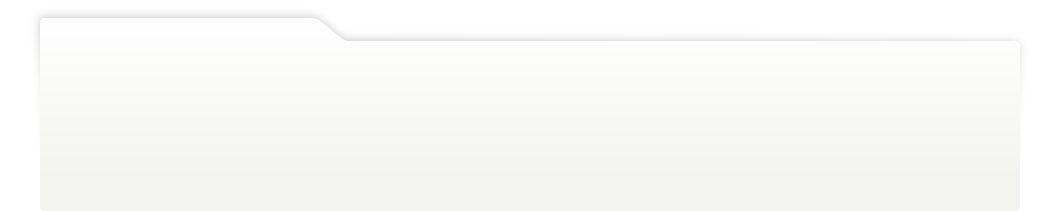
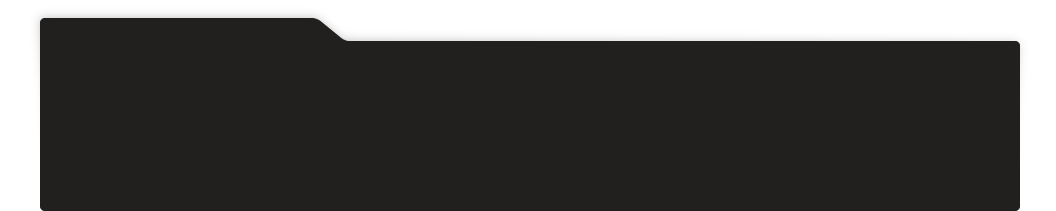
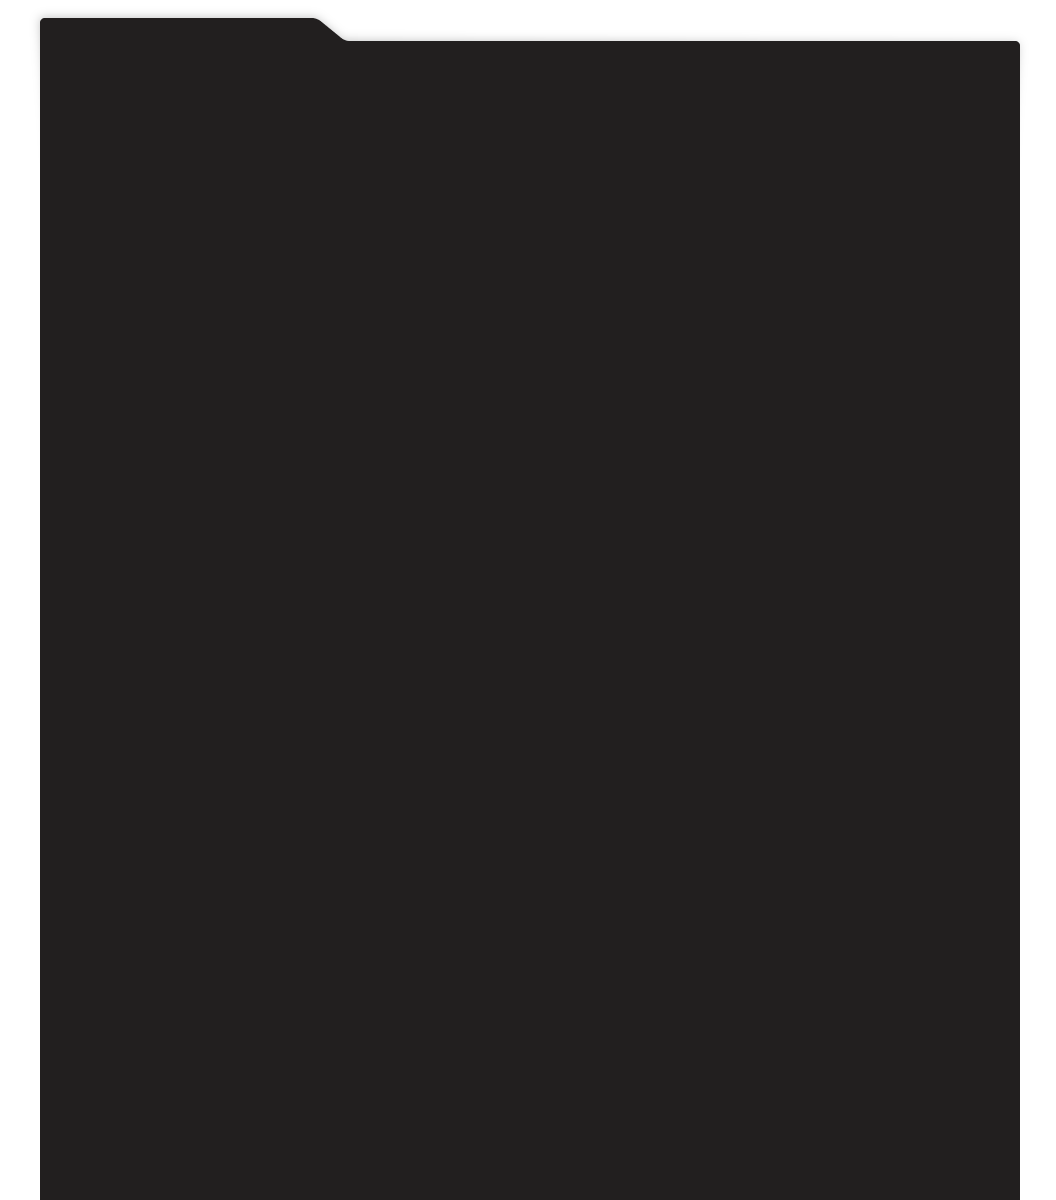
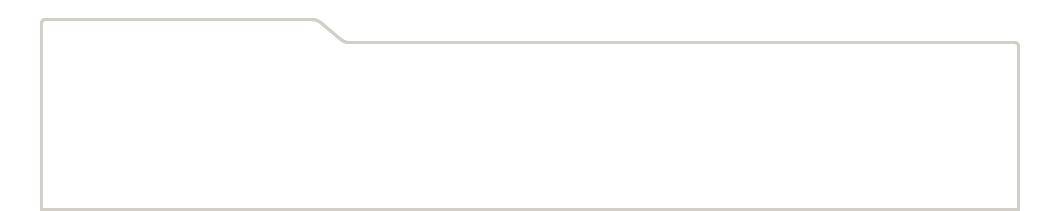
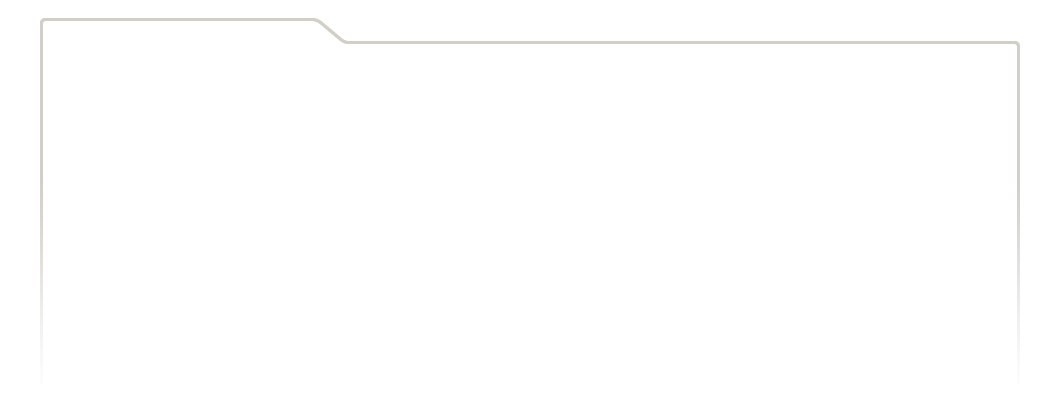
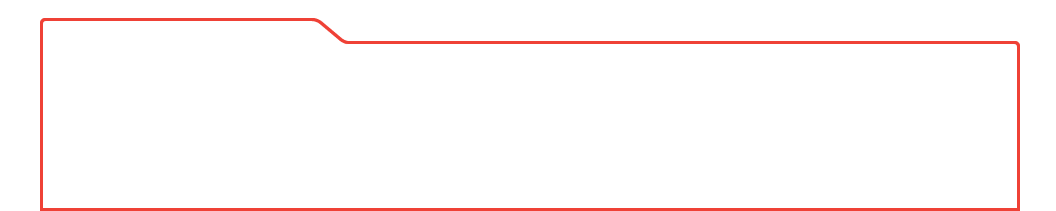
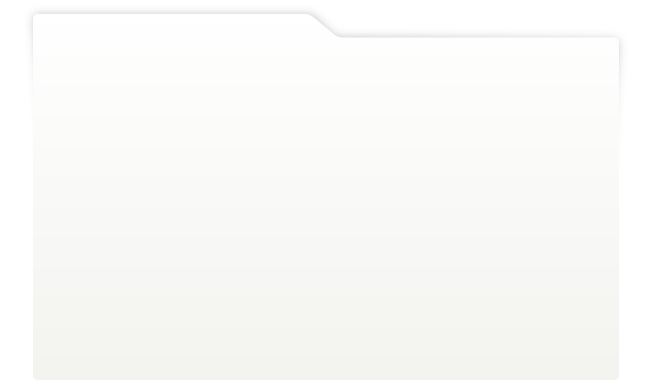
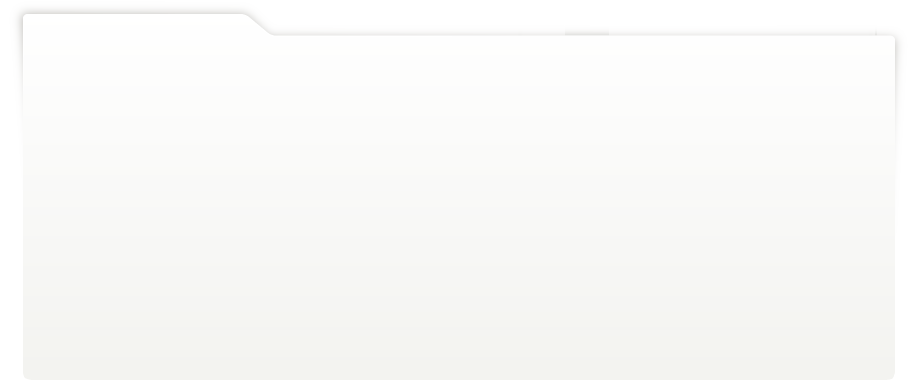
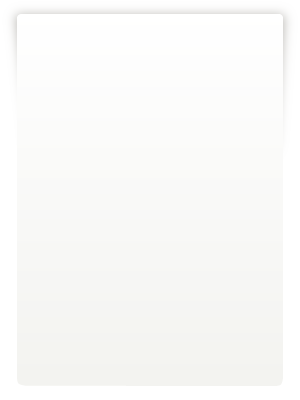
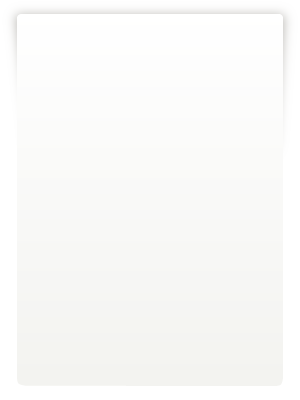
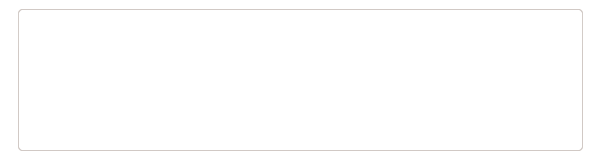
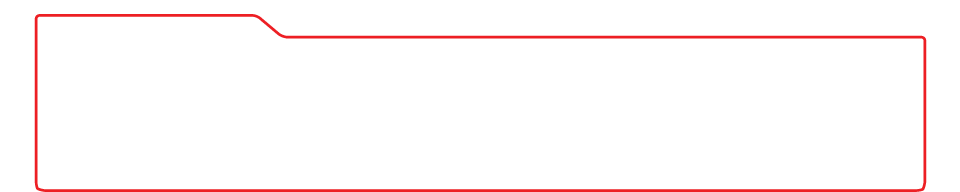
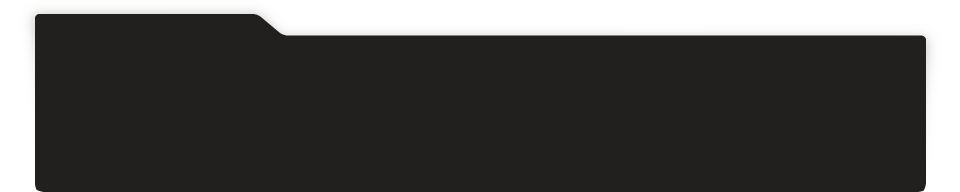
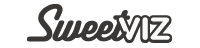
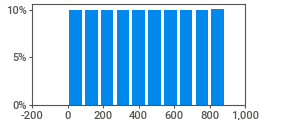
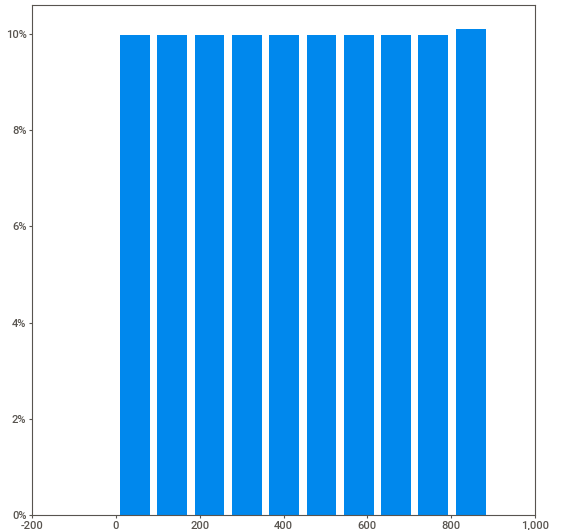
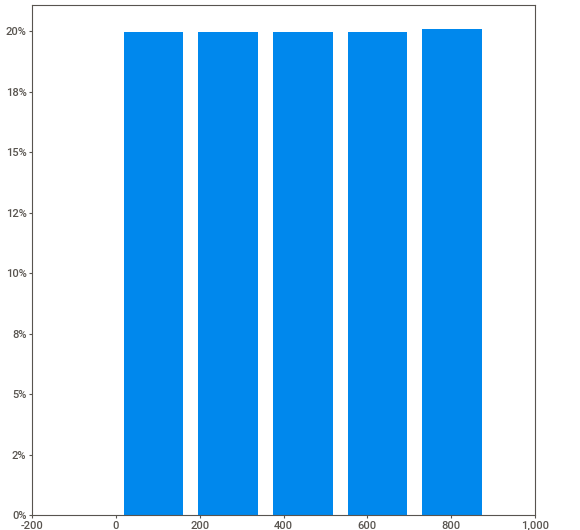
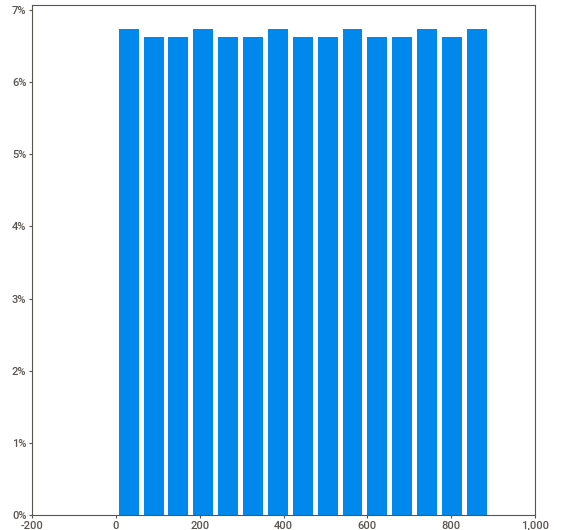
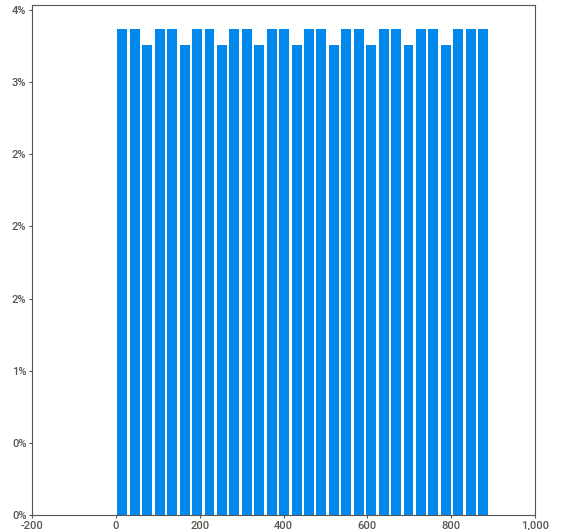
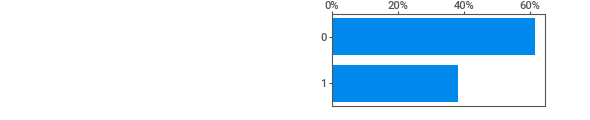
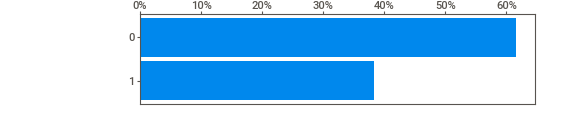
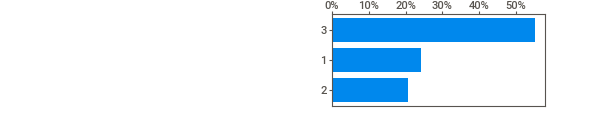
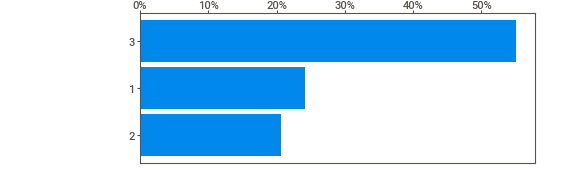
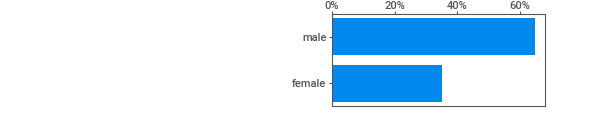
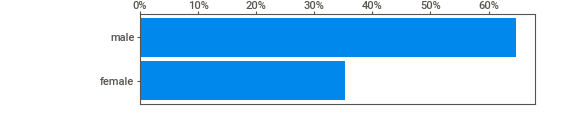
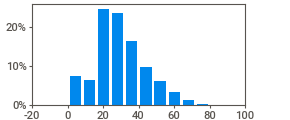
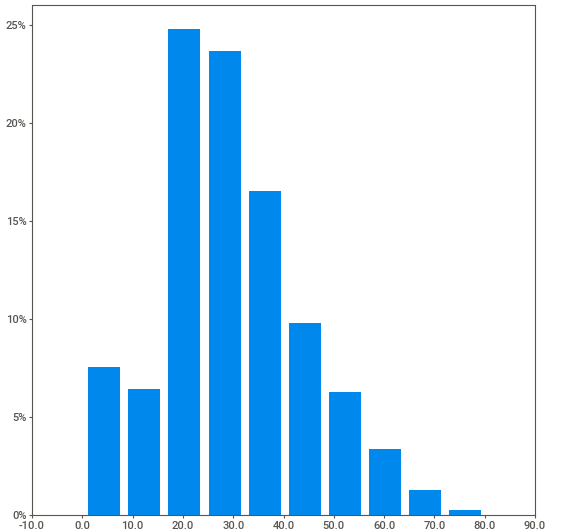
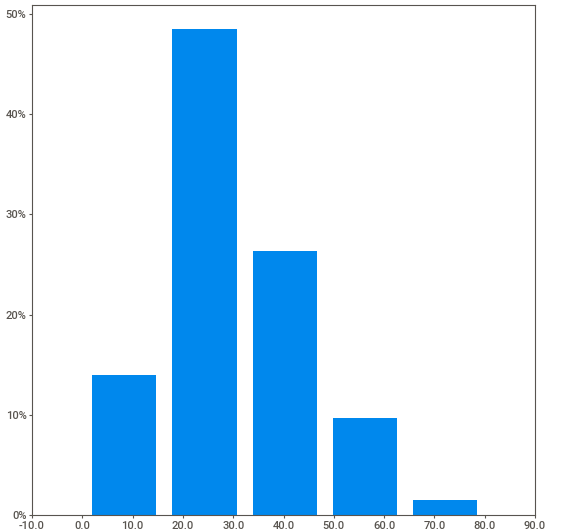
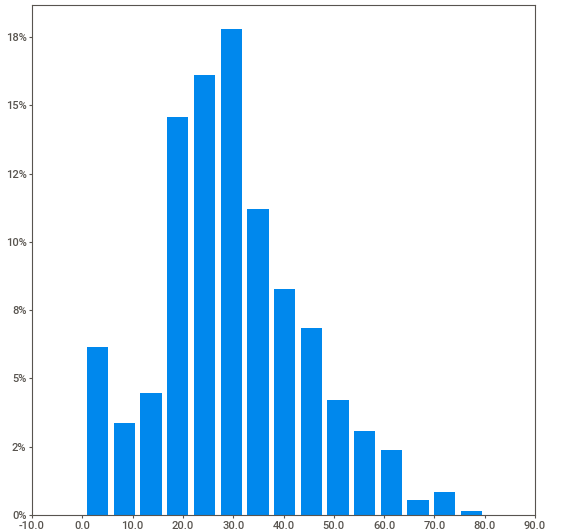
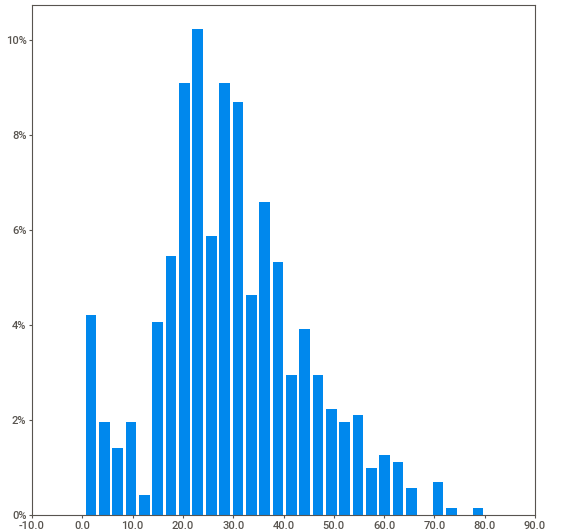
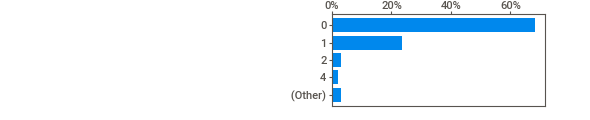
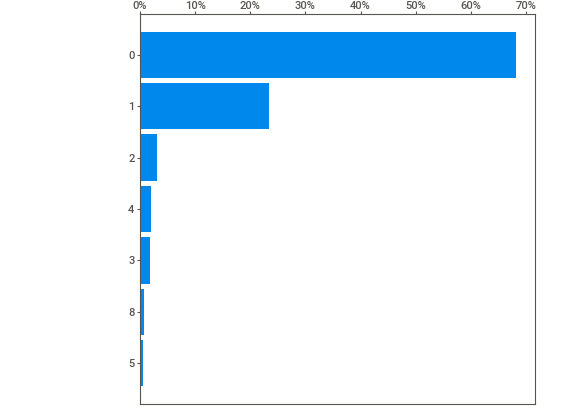
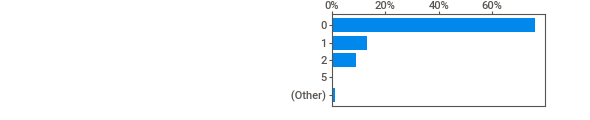
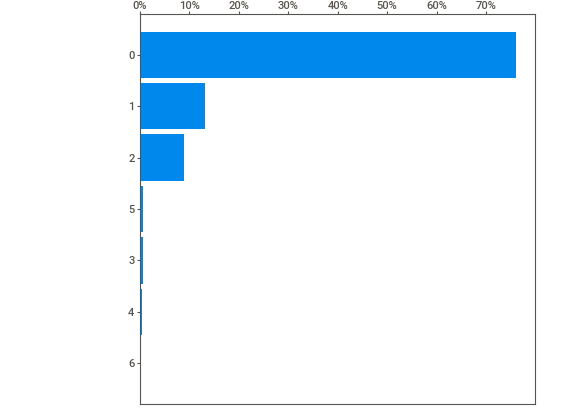
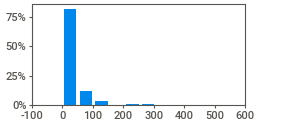
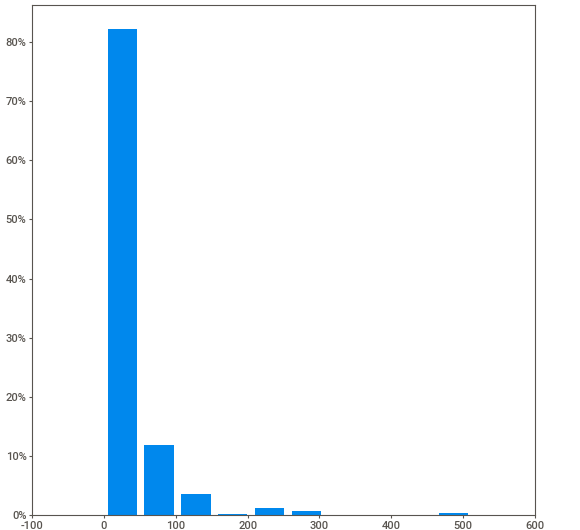
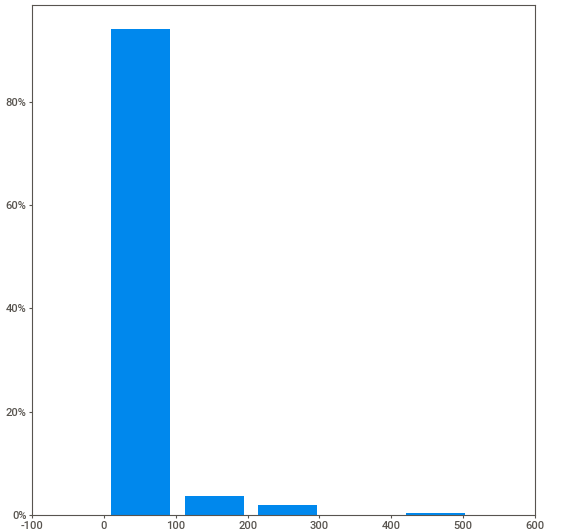
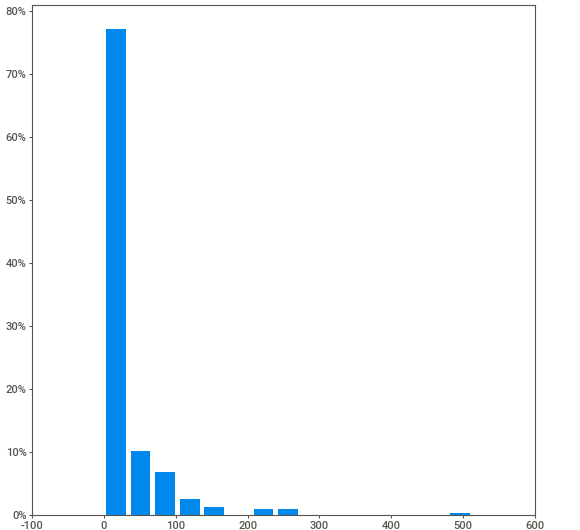
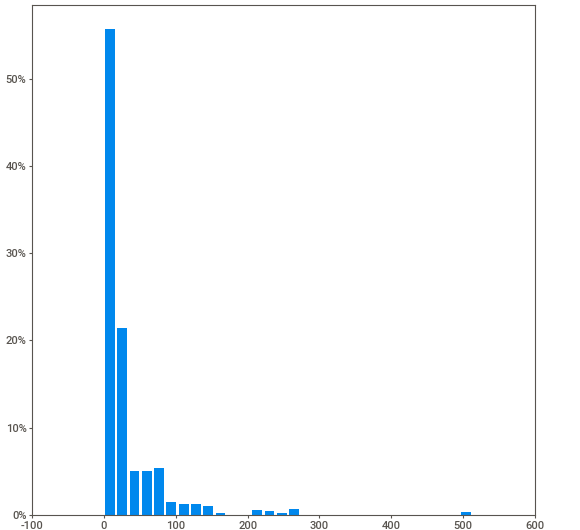
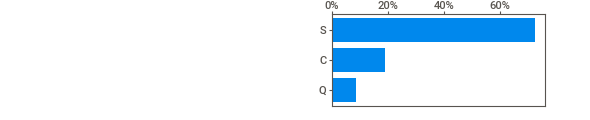
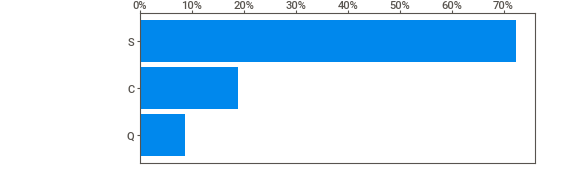
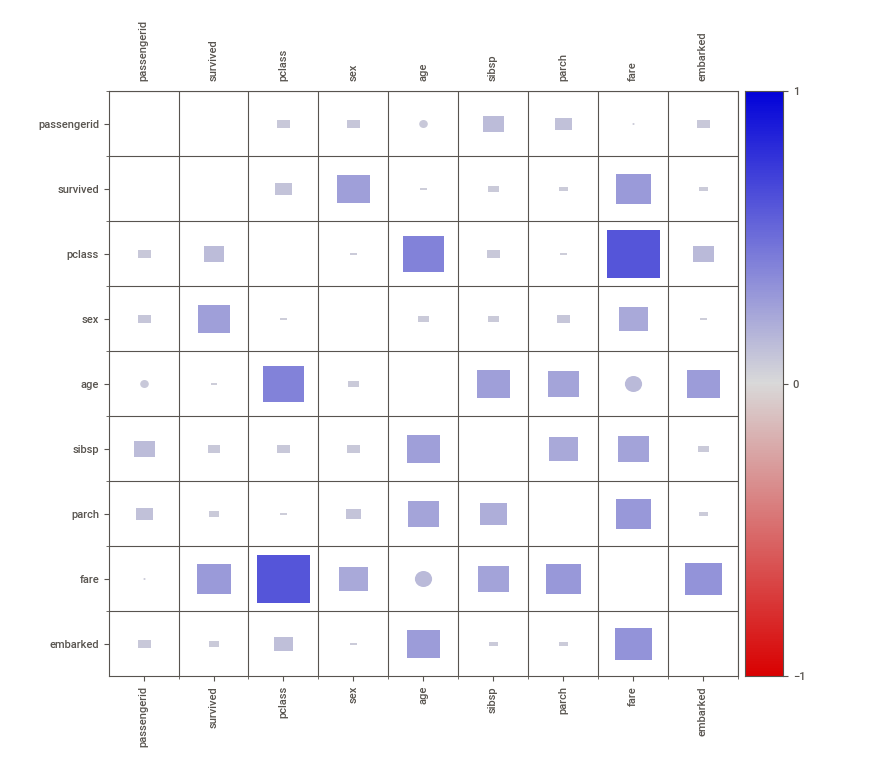
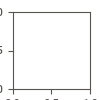

In [0]:
# Display the report inside the Databricks notebook.
# Open each feature in the report to inspect its distribution and missing values.

titanic_basic_report.show_notebook()

### Read the first report

Start with the report overview, then work through the features.

Look for:

1. The number of rows and columns.
2. Columns with missing values.
3. Numeric distributions that appear skewed.
4. Categorical fields with uneven group sizes.
5. Identifier fields that are useful for tracing records but less useful for analysis.

### Quick check: two minutes

Use pandas to confirm the missing values highlighted by Sweetviz.

Return only columns that contain at least one missing value, ordered from most missing to least missing.

In [0]:
# Your turn.
# Hint 1: start with titanic.isna().sum().
# Hint 2: keep counts greater than zero.
# Hint 3: sort the result from highest to lowest.


In [0]:
# Coach answer.
# This gives the exact missing count behind the Sweetviz summary.

titanic_missing = titanic.isna().sum()
titanic_missing[titanic_missing > 0].sort_values(ascending=False)

cabin       687
age         177
embarked      2
dtype: int64

## Step 5: build a target-focused Sweetviz report

A general report describes the whole dataset. A target-focused report adds a specific outcome that we want to understand.

For Titanic, `survived` is already a numeric 0 and 1 field, so no conversion is required. We first confirm its values, then use it as the target.

In [0]:
# Check the target before using it.
# We expect only 0 and 1, with no unexpected values.

titanic["survived"].value_counts(dropna=False)

0    549
1    342
Name: survived, dtype: int64

In [0]:
# Build a report that focuses on survival.
# Sweetviz will show how the other features relate to the target.

titanic_target_report = sv.analyze(titanic, target_feat="survived")

                                             |          | [  0%]   00:00 -> (? left)


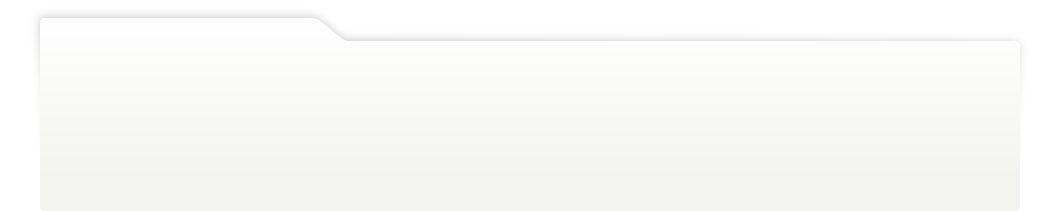
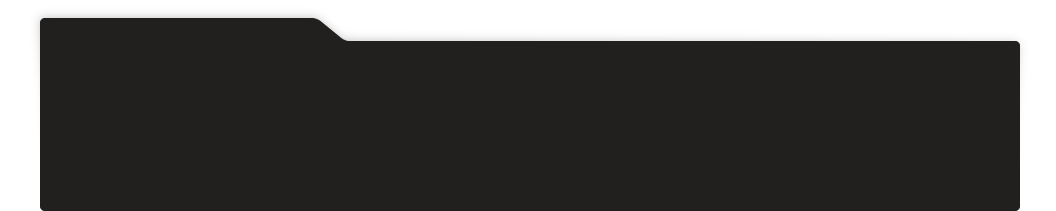
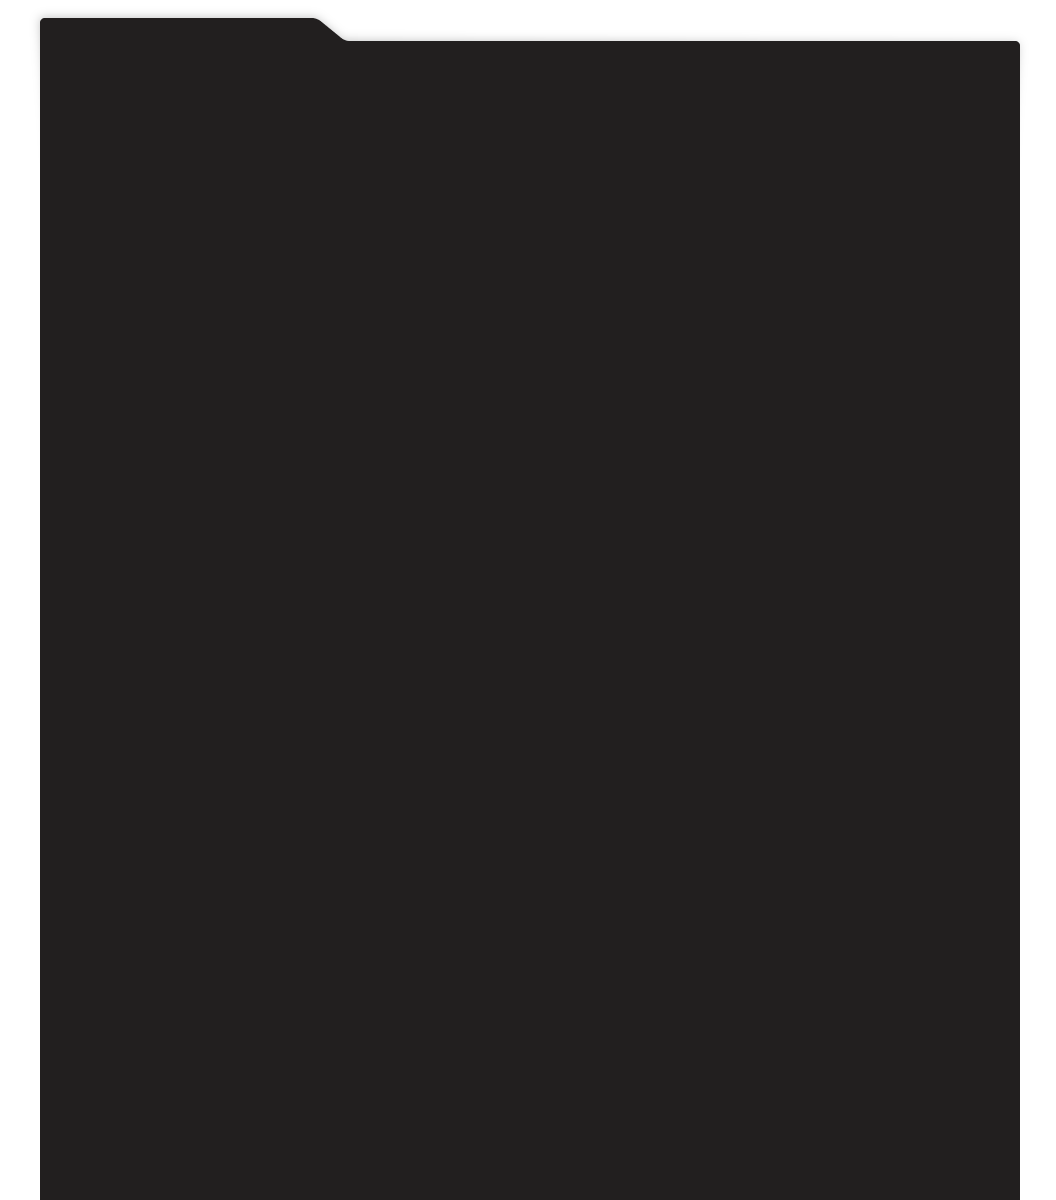
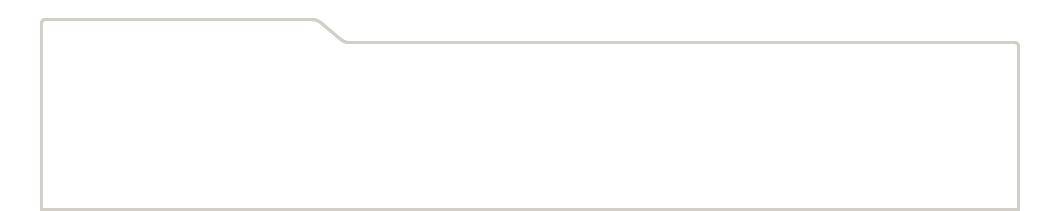
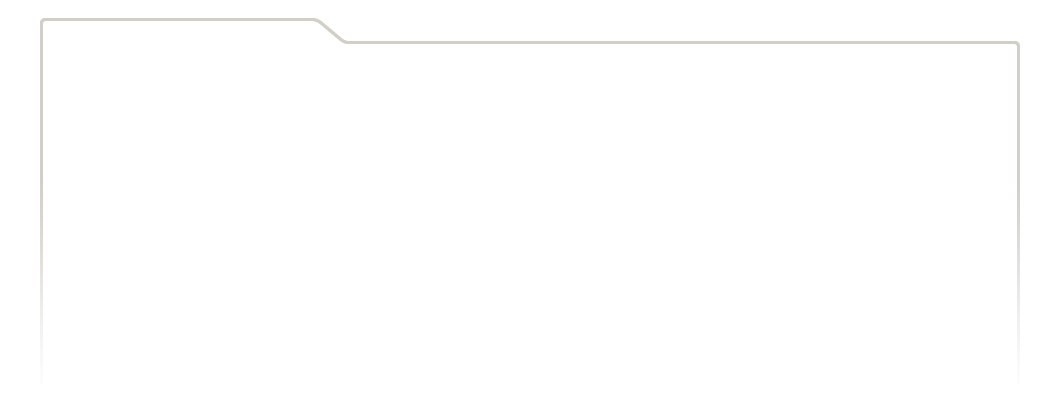
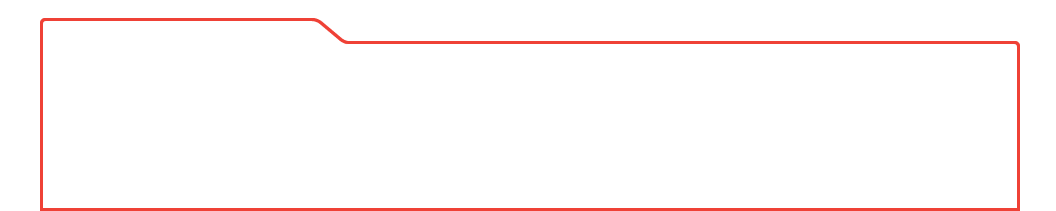
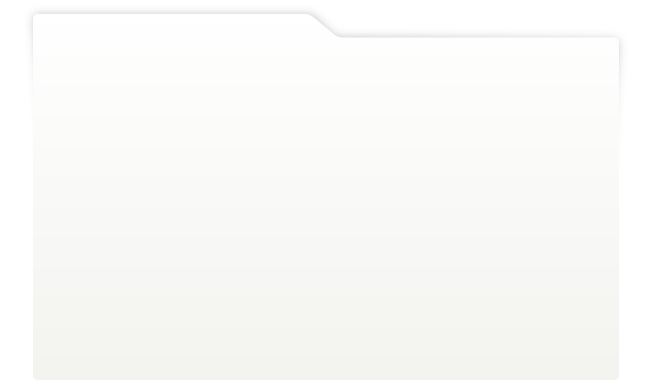
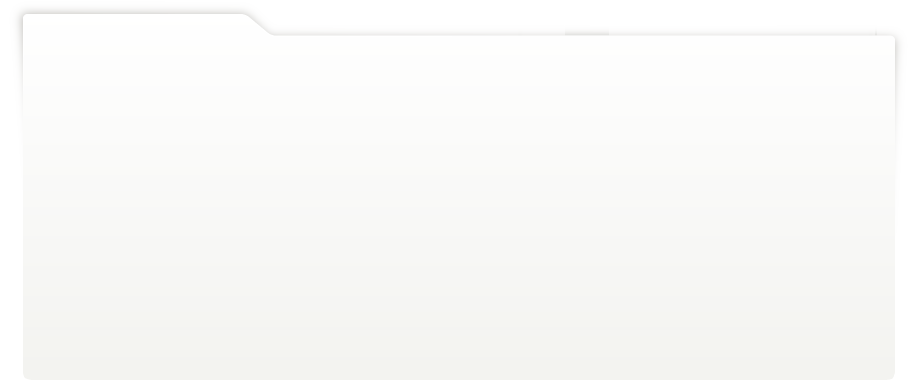
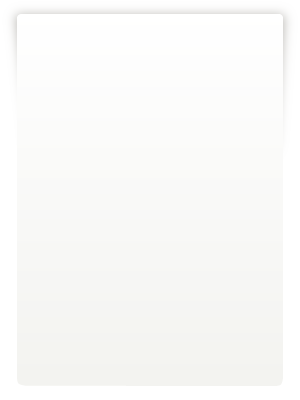
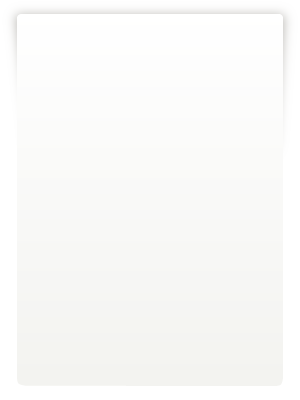
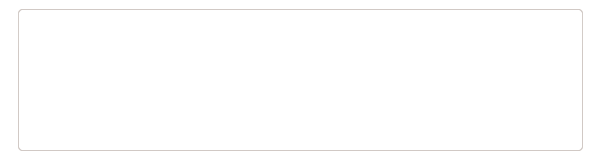
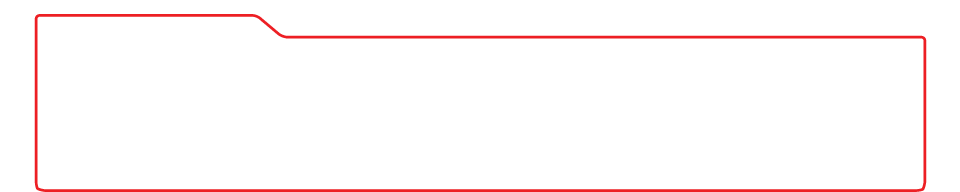
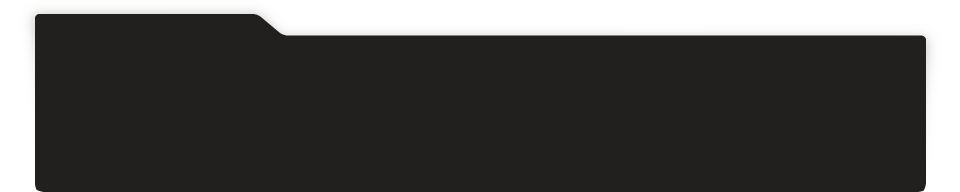
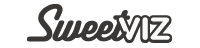
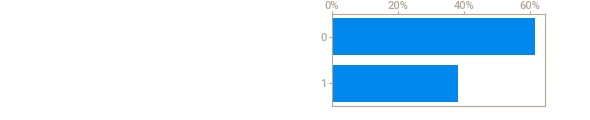
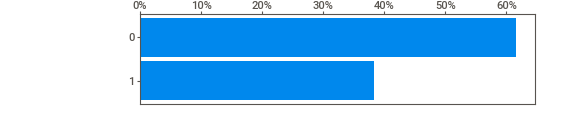
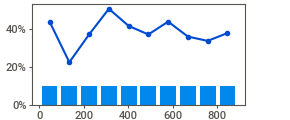
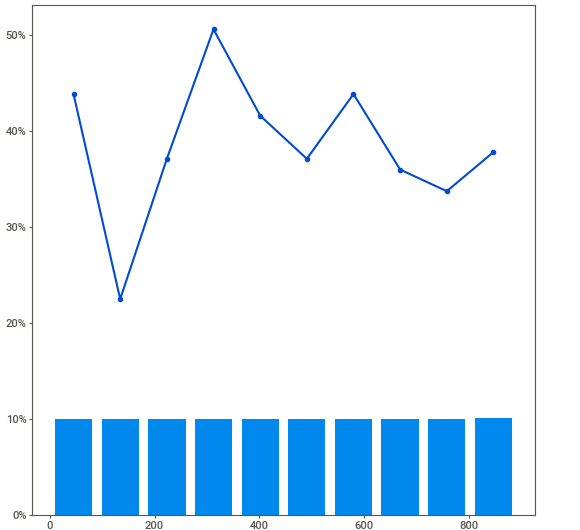
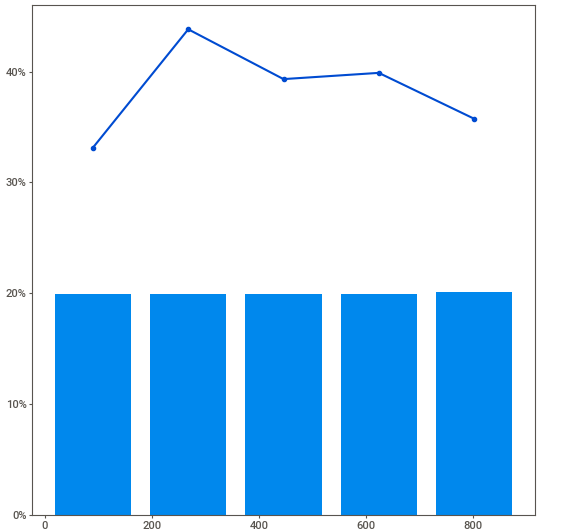
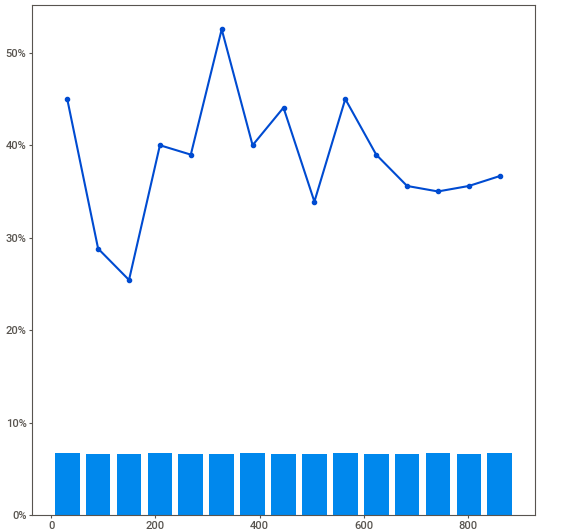
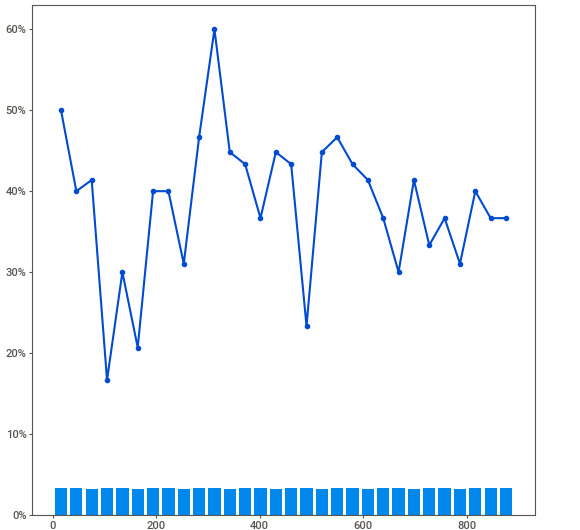
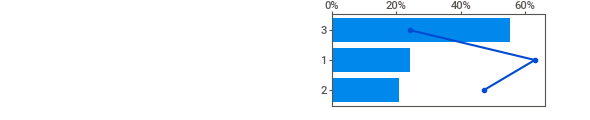
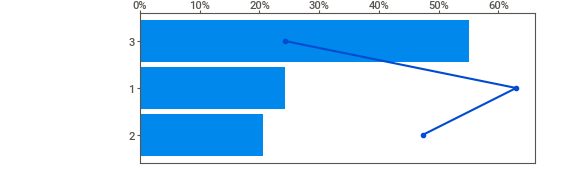
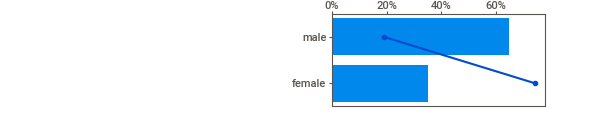
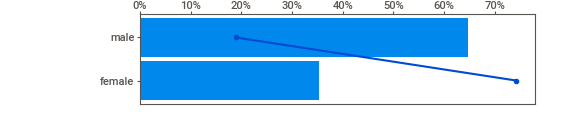
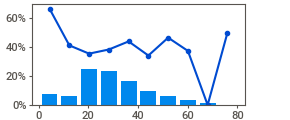
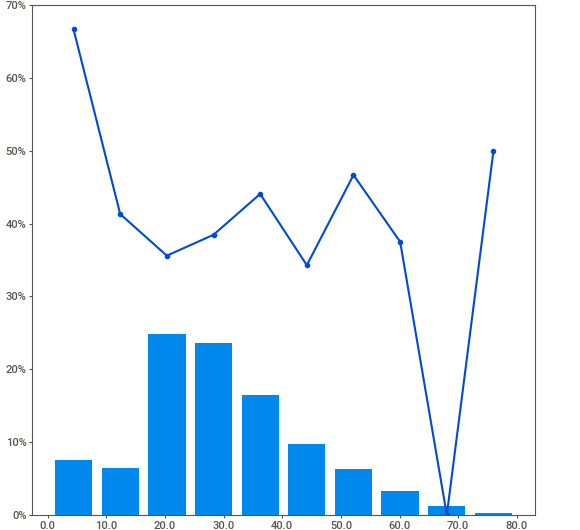
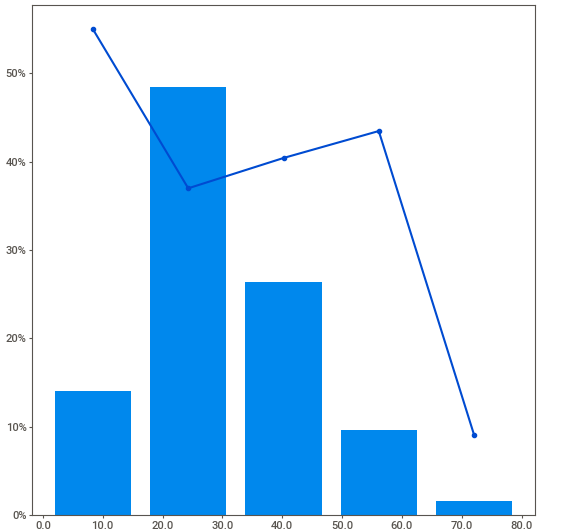
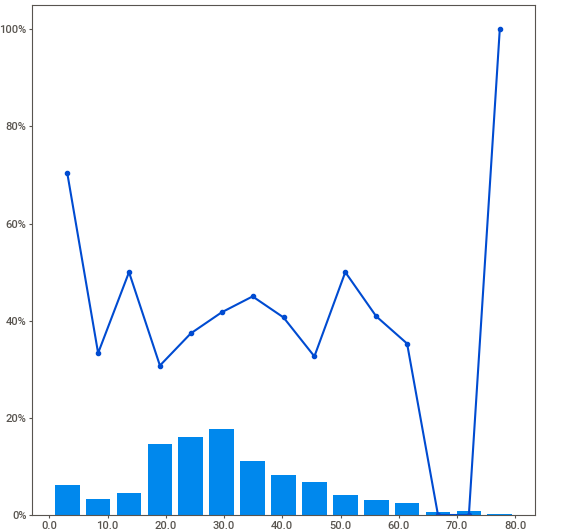
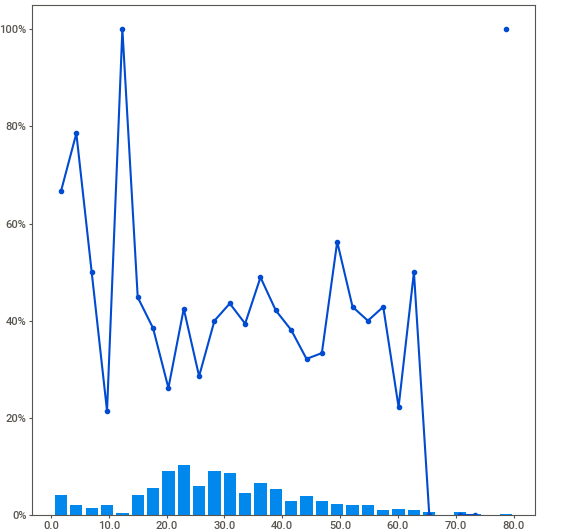
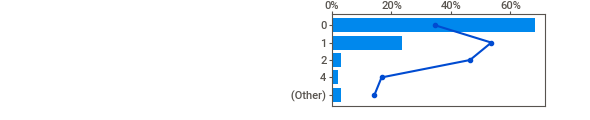
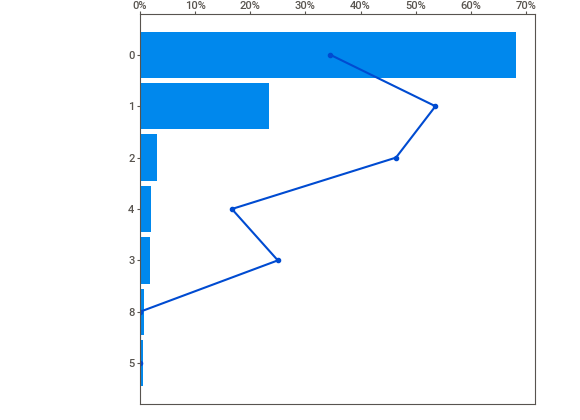
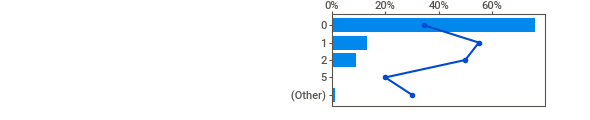
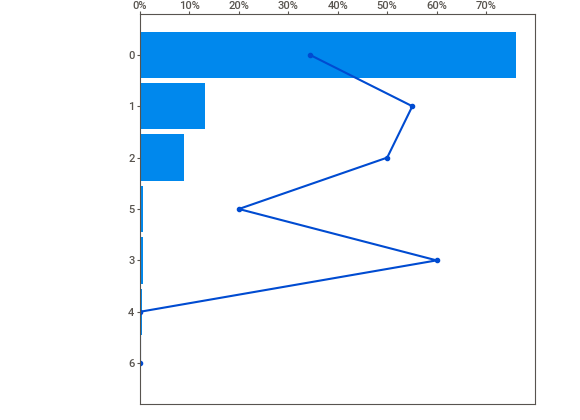
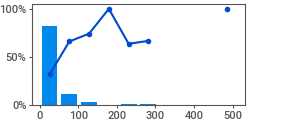
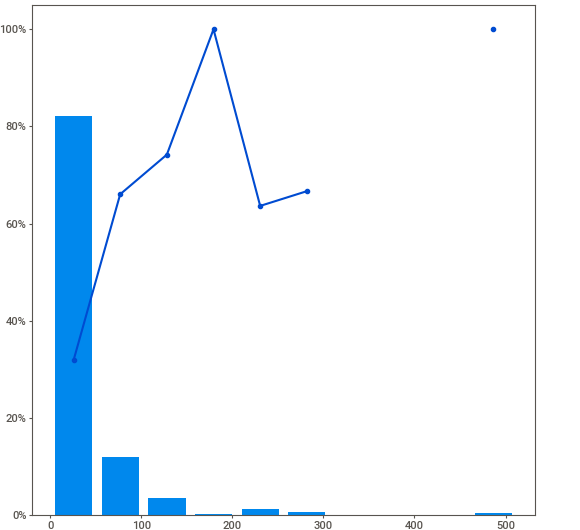
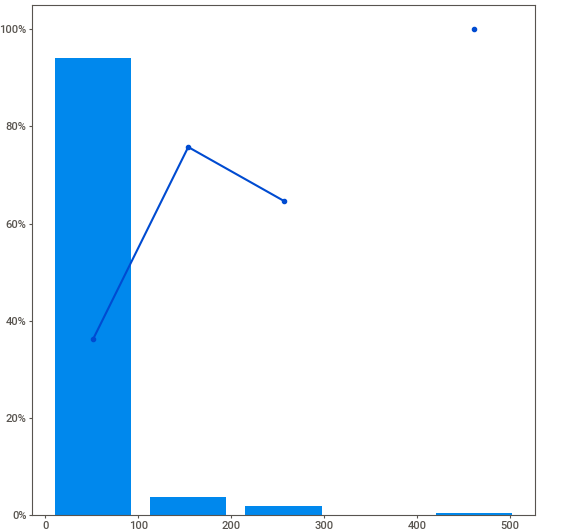
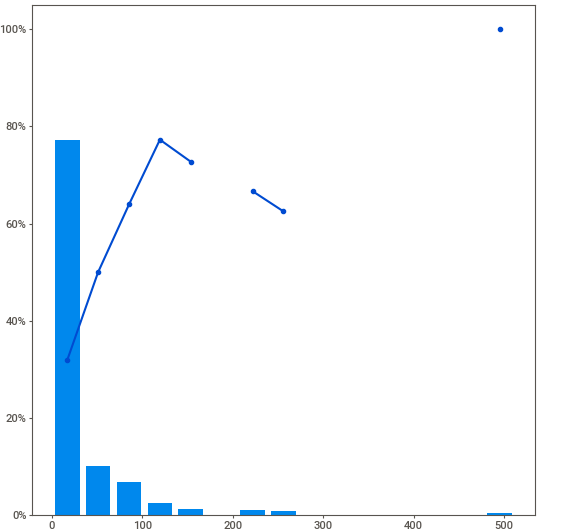
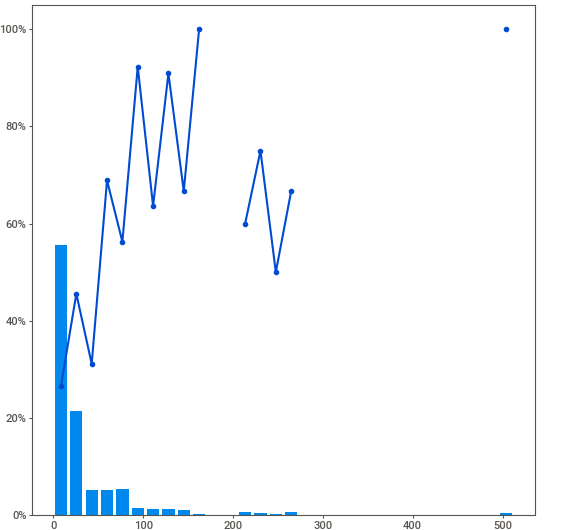
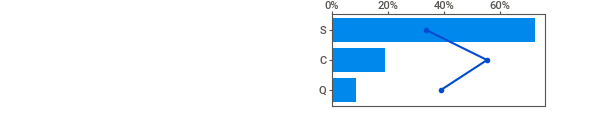
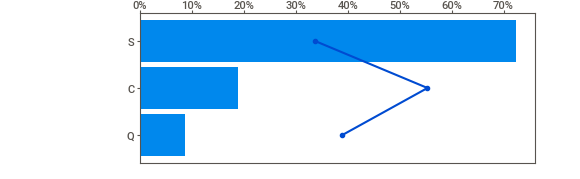
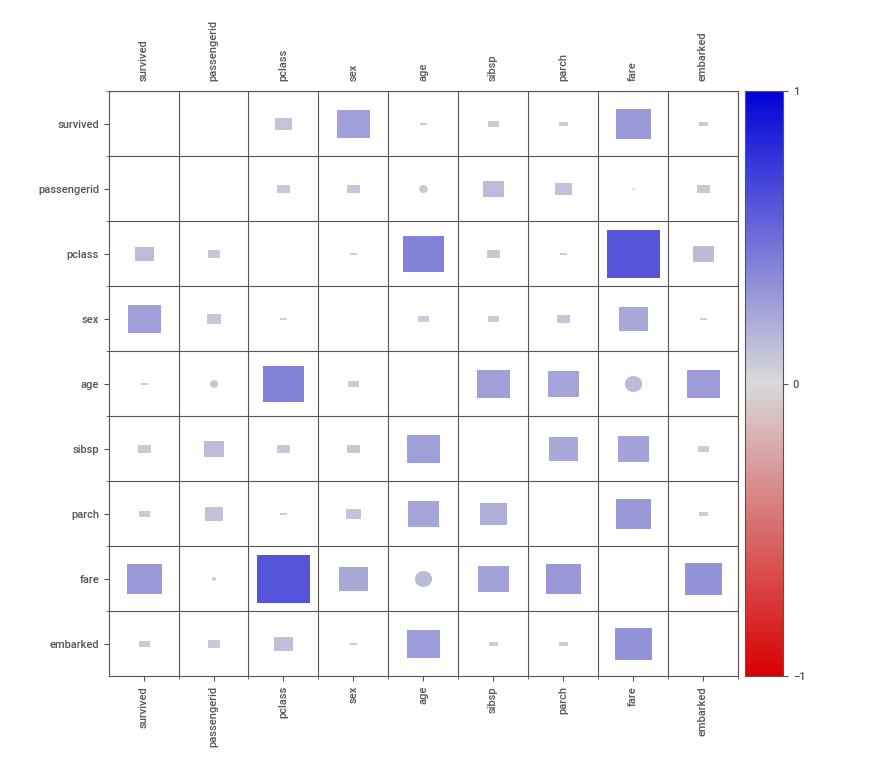
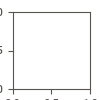

In [0]:
# Display the target-focused report in Databricks.
# Compare this report with the earlier general profile.

titanic_target_report.show_notebook()

<a id="reading"></a>
# Section 5: Reading a Sweetviz report

Do not scroll through the report without a plan.

Use this reading order:

1. Start with the overview.
2. Check row count and feature count.
3. Check missing values.
4. Review the target balance when a target is used.
5. Look at the strongest relationships.
6. Select one or two findings for manual follow up.

The report helps us form questions. Pandas gives us the exact evidence needed to answer them.

## Follow up 1: survival by sex

The target report should draw attention to differences between passenger groups.

We now calculate the exact survival rate by sex so the finding can be explained with a clear number.

In [0]:
# Count passengers and calculate the mean survival value for each group.
# The mean of a 0 and 1 column is the proportion that survived.

survival_by_sex = titanic.groupby("sex", as_index=False).agg(
    passengers=("survived", "count"),
    survival_rate=("survived", "mean")
)

In [0]:
# Add a percentage column for easier interpretation.
# The original decimal rate is kept for analysis.

survival_by_sex["survival_rate_pct"] = survival_by_sex["survival_rate"] * 100
survival_by_sex

,sex,passengers,survival_rate,survival_rate_pct
0,female,314,0.742038,74.203822
1,male,577,0.188908,18.890815


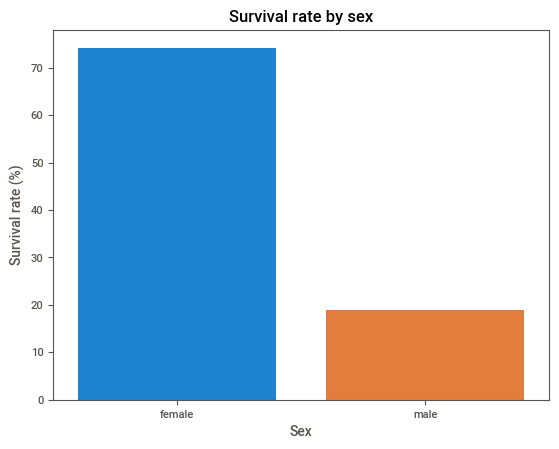

In [0]:
# A bar chart is suitable because we are comparing two categories.
# The table above provides the exact figures behind the chart.

sns.barplot(data=survival_by_sex, x="sex", y="survival_rate_pct")
plt.title("Survival rate by sex")
plt.xlabel("Sex")
plt.ylabel("Survival rate (%)")
plt.show()

## Follow up 2: survival by passenger class

Passenger class is another relationship worth validating.

We compare the number of passengers, survival rate and average fare for each class.

In [0]:
# Summarise survival and fare by passenger class.
# Sorting by Pclass keeps the natural class order in the output.

survival_by_class = titanic.groupby("pclass", as_index=False).agg(
    passengers=("survived", "count"),
    survival_rate=("survived", "mean"),
    average_fare=("fare", "mean")
).sort_values("pclass")

In [0]:
# Add a percentage version of the survival rate.
# Review passenger count before comparing percentages.

survival_by_class["survival_rate_pct"] = survival_by_class["survival_rate"] * 100
survival_by_class

,pclass,passengers,survival_rate,average_fare,survival_rate_pct
0,1,216,0.629630,84.154687,62.962963
1,2,184,0.472826,20.662183,47.282609
2,3,491,0.242363,13.675550,24.236253


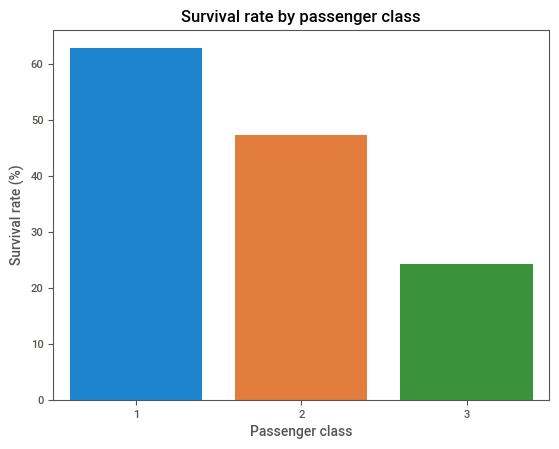

In [0]:
# A bar chart makes the three passenger classes easy to compare.
# The y axis uses a percentage because that is easier to discuss.

sns.barplot(data=survival_by_class, x="pclass", y="survival_rate_pct")
plt.title("Survival rate by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate (%)")
plt.show()

### Quick check: two minutes

Sweetviz shows age as a continuous variable. For a short group comparison, create an `age_band` column and calculate survival by age band.

Use these groups:

- Child: 0 to 12
- Teen: over 12 to 18
- Young adult: over 18 to 35
- Adult: over 35 to 60
- Older adult: over 60 to 100

In [0]:
# Your turn.
# Hint 1: use pd.cut() to create age_band.
# Hint 2: group by age_band.
# Hint 3: count survived and calculate its mean.


In [0]:
# Coach answer: create readable age groups.
# Missing ages remain missing and are not forced into a group.

titanic["age_band"] = pd.cut(
    titanic["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young adult", "Adult", "Older adult"],
    include_lowest=True
)

In [0]:
# Coach answer: calculate survival by age band.
# observed=True returns only age groups represented in the data.

survival_by_age_band = titanic.groupby("age_band", observed=True, as_index=False).agg(
    passengers=("survived", "count"),
    survival_rate=("survived", "mean")
)

In [0]:
# Sort the result so the highest survival rate appears first.
# Check passenger count before treating a rate as important.

survival_by_age_band.sort_values("survival_rate", ascending=False)

,age_band,passengers,survival_rate
0,Child,69,0.579710
1,Teen,70,0.428571
3,Adult,195,0.400000
2,Young adult,358,0.382682
4,Older adult,22,0.227273


## Titanic section conclusion

Sweetviz gave us a fast view of the dataset and helped identify relationships worth investigating.

The pandas follow ups then gave us exact counts and rates. This is the main workflow for the rest of the notebook:

1. Profile broadly.
2. Select a useful finding.
3. Validate it manually.
4. Explain it in plain English.

<a id="superstore-lab"></a>
# Section 6: Superstore live class lab

Superstore is the main practical section.

The class will work in 15 minute chunks. At each exercise point, learners complete the task, then the coach returns to work through the solution and take questions.

The investigation focuses on profitability and discount behaviour. The aim is to use Sweetviz for the first profile, then use pandas and charts for focused follow up.

## Lab chunk 1: prepare and inspect Superstore

### Task

Prepare `store_raw` for analysis.

You should:

1. Copy the raw DataFrame.
2. Standardise the column names.
3. Check the cleaned names.
4. Check the data types inferred by pandas.

Do not convert numeric columns automatically. Convert a column only when the data type check shows that it is needed.

In [0]:
# Your turn.
# Hint 1: start with store = store_raw.copy().
# Hint 2: use string methods on store.columns.
# Hint 3: replace spaces and hyphens with underscores.
# Hint 4: use .dtypes to check the inferred types.


### Coach solution: copy and standardise the columns

This step improves usability without changing the values in the dataset.

In [0]:
# Work on a copy so the S3 data remains available in its original form.
# Any preparation is applied only to store.

store = store_raw.copy()

In [0]:
# Use lowercase names and underscores for consistent pandas code.
# The second line changes Sub-Category into sub_category.

store.columns = store.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
store.columns = store.columns.str.replace("-", "_", regex=False)

In [0]:
# Confirm the cleaned column names before using them later.
# This prevents avoidable spelling errors in the lab.

store.columns.tolist()

['row_id',
 'order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_id',
 'customer_name',
 'segment',
 'country',
 'city',
 'state',
 'postal_code',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit']

In [0]:
# Check the data types inferred by pandas.
# Sales, Quantity, Discount and Profit should already be numeric.

store.dtypes

row_id             int32
order_id          object
order_date        object
ship_date         object
ship_mode         object
customer_id       object
customer_name     object
segment           object
country           object
city              object
state             object
postal_code        int32
region            object
product_id        object
category          object
sub_category      object
product_name      object
sales             object
quantity          object
discount          object
profit           float64
dtype: object

In [0]:
# Look at a few prepared rows.
# This is the final check before automated profiling.

store.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164


### Coach interpretation

Because pandas inferred the data types when it read the file, the main measures should already have numeric data types.

There is no benefit in converting a numeric column to numeric again. The inspection step tells us whether preparation is actually required.

## Lab chunk 2: build the first Superstore report

### Task

Create and display a standard Sweetviz report for the prepared `store` DataFrame.

Do not set a target yet. This first report is a broad profile of the dataset.

In [0]:
# Your turn.
# Hint 1: pass store into sv.analyze().
# Hint 2: save the result to a clearly named variable.
# Hint 3: call .show_notebook() in the next cell.


### Coach solution: general Superstore profile

The first report uses the same two-step pattern as Titanic.

In [0]:
# Build a general automated EDA report for Superstore.
# No target is used at this stage.

store_basic_report = sv.analyze(store)

                                             |          | [  0%]   00:00 -> (? left)


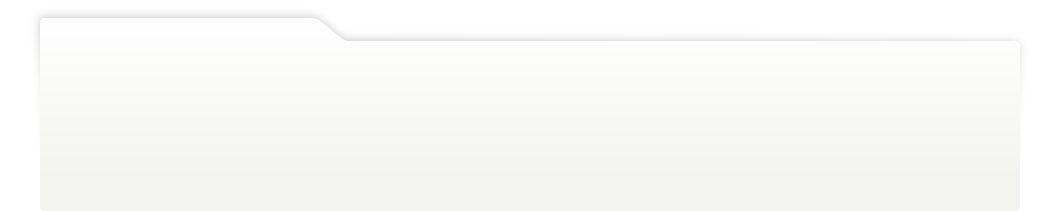
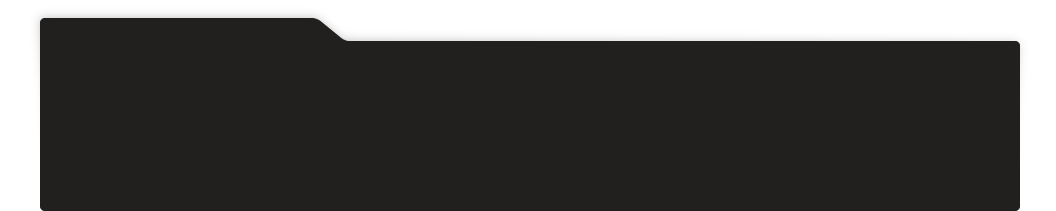
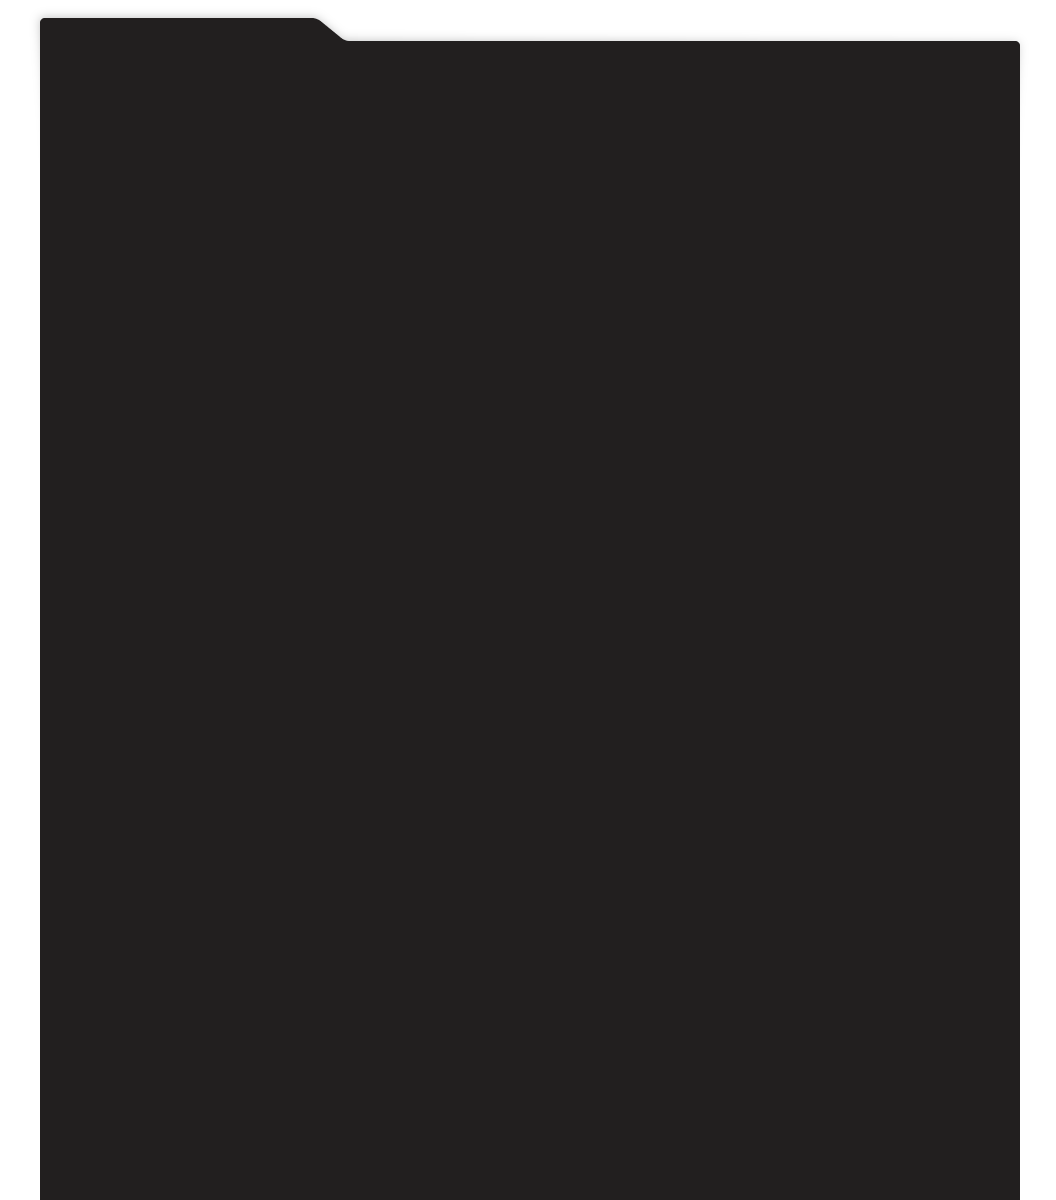
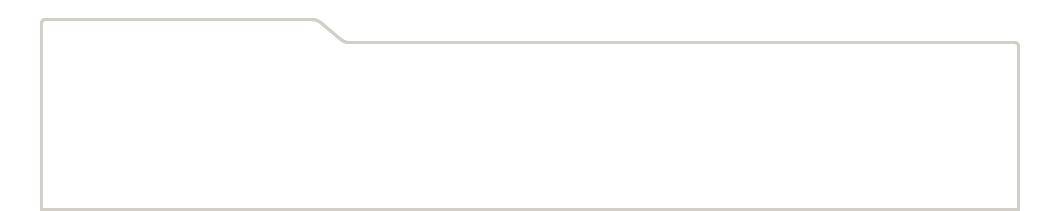
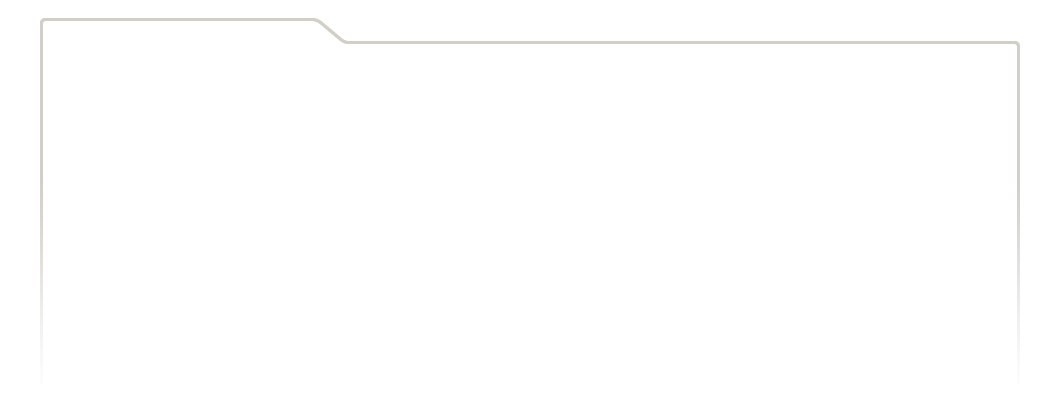
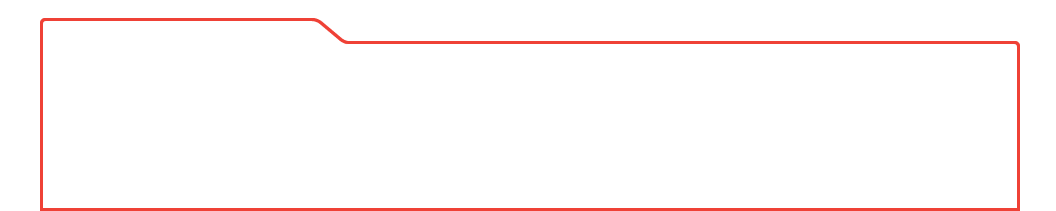
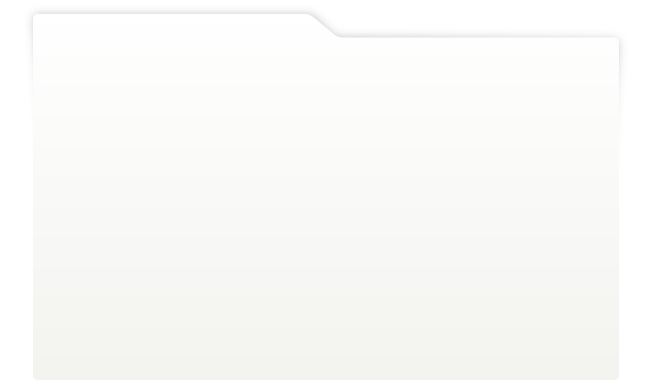
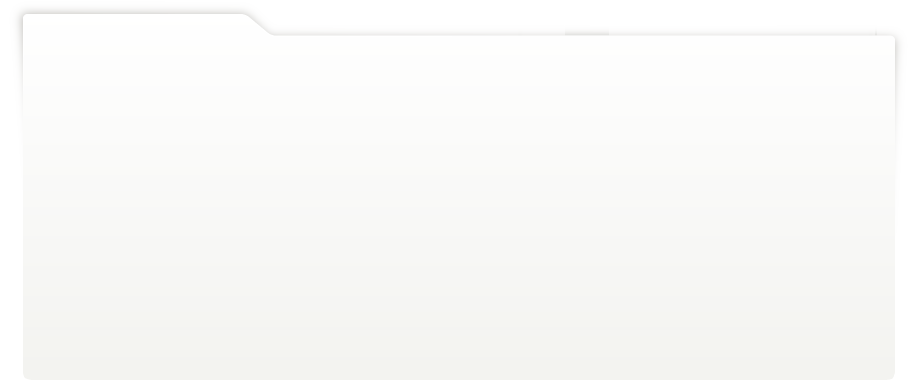
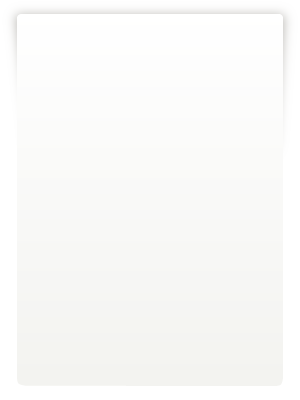
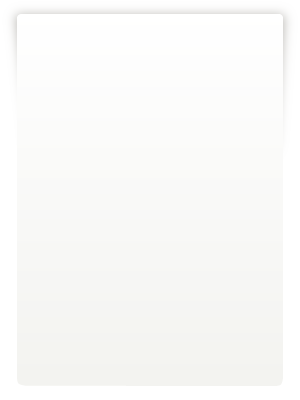
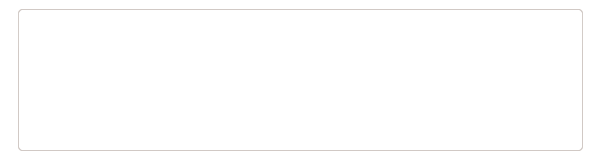
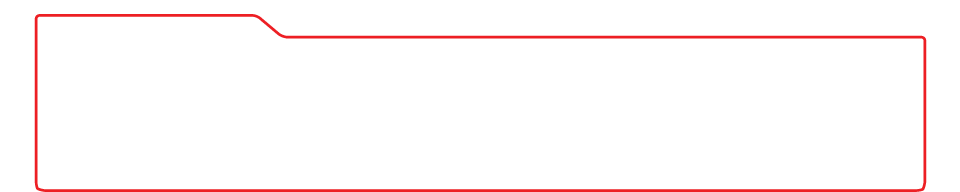
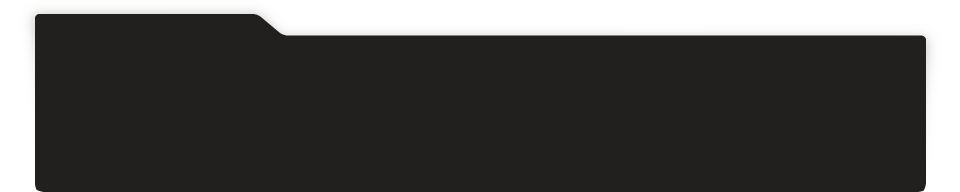
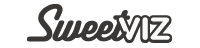
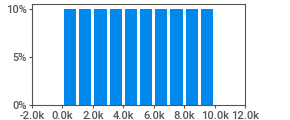
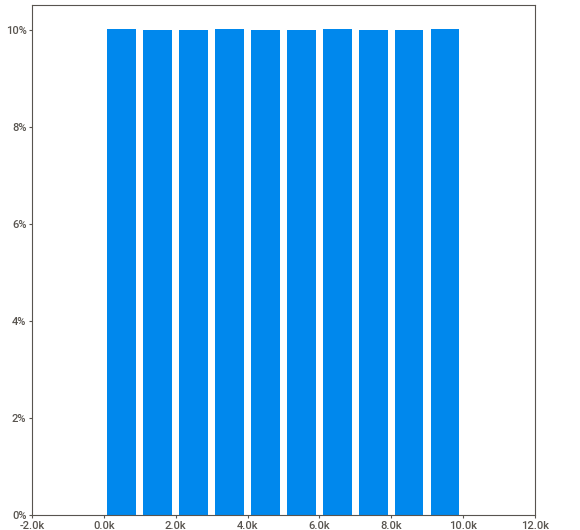
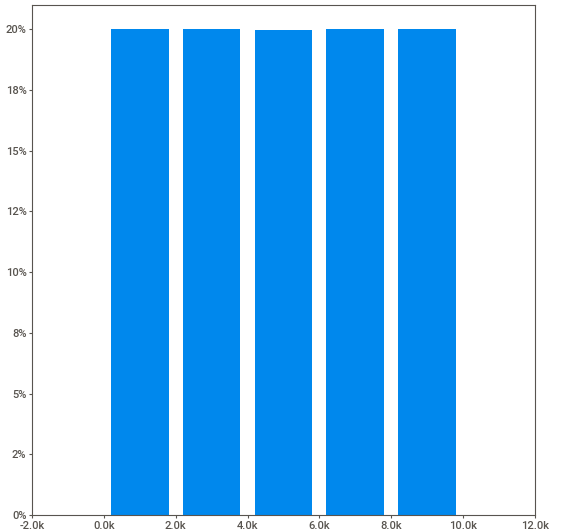
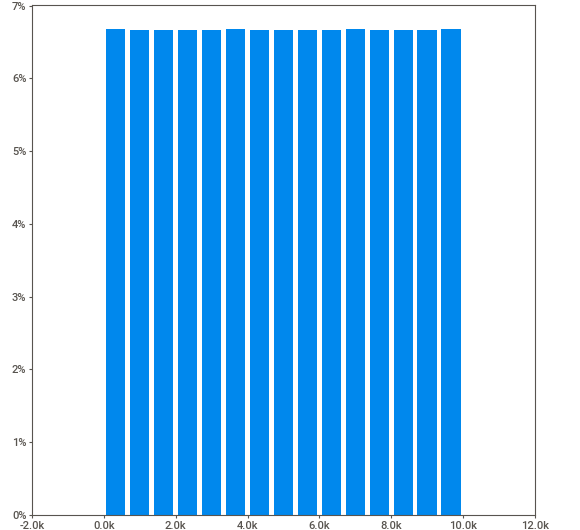
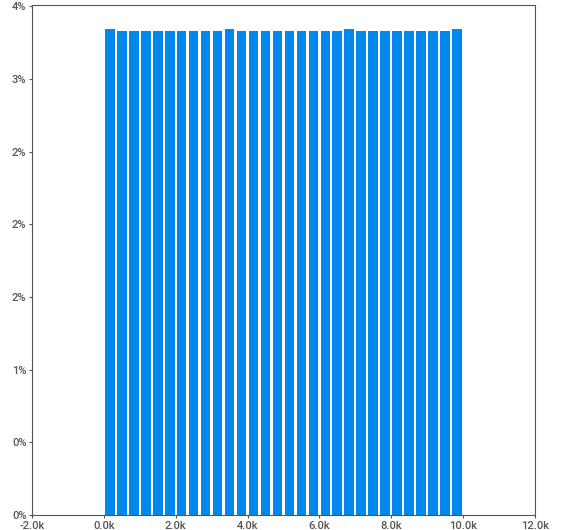
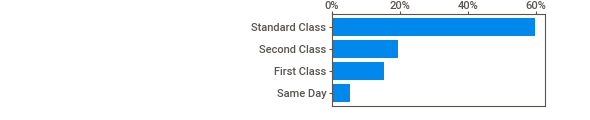
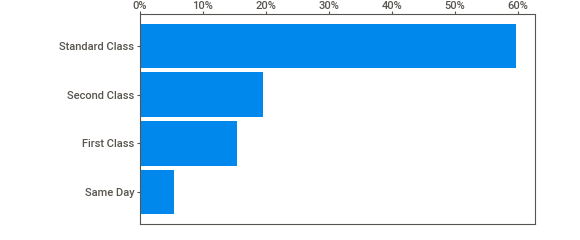
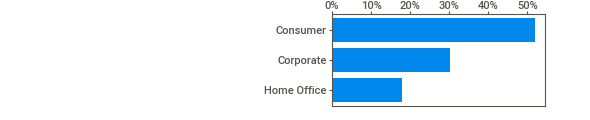
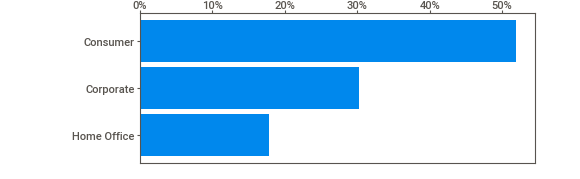
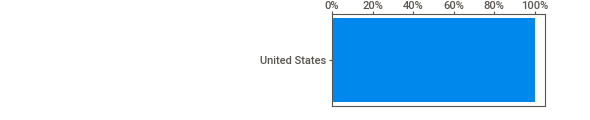
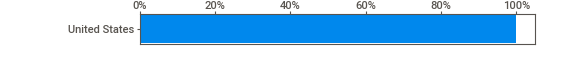
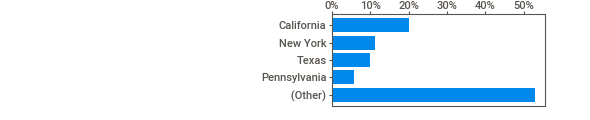
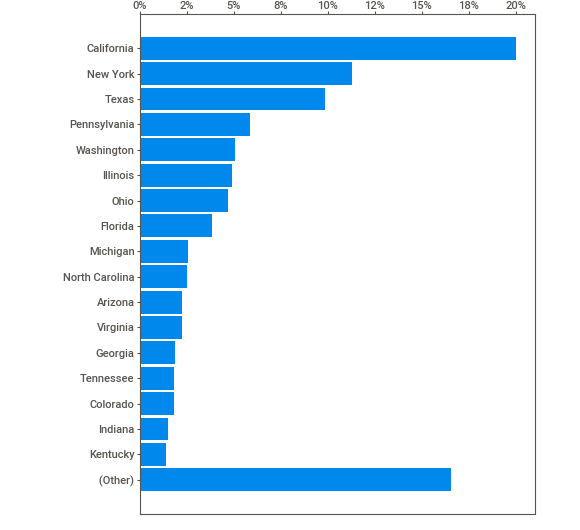
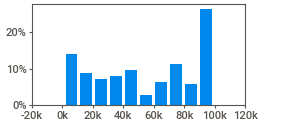
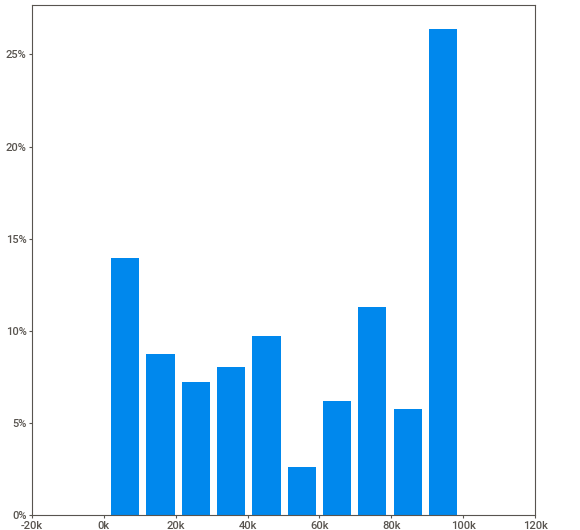
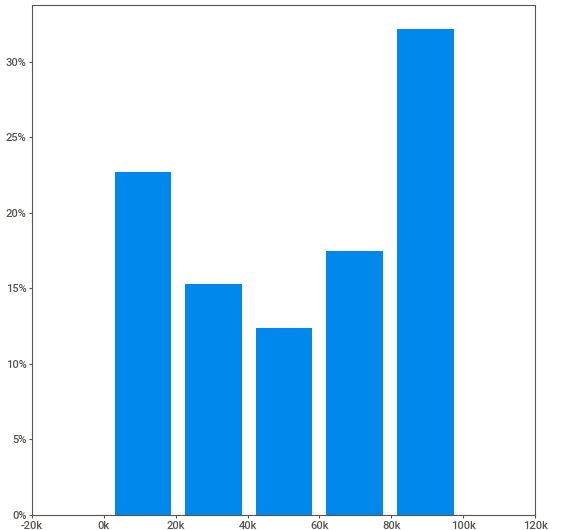
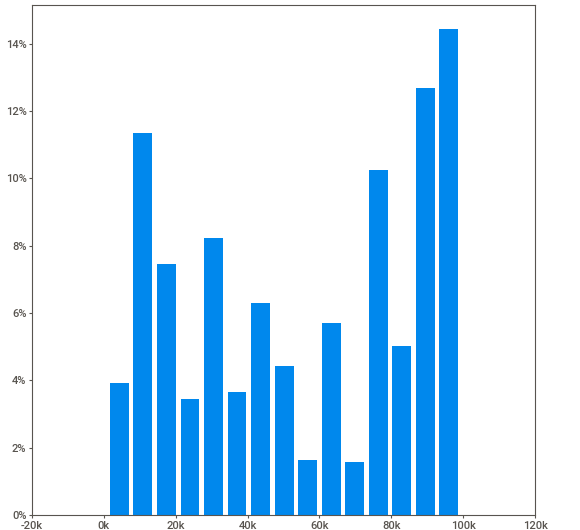
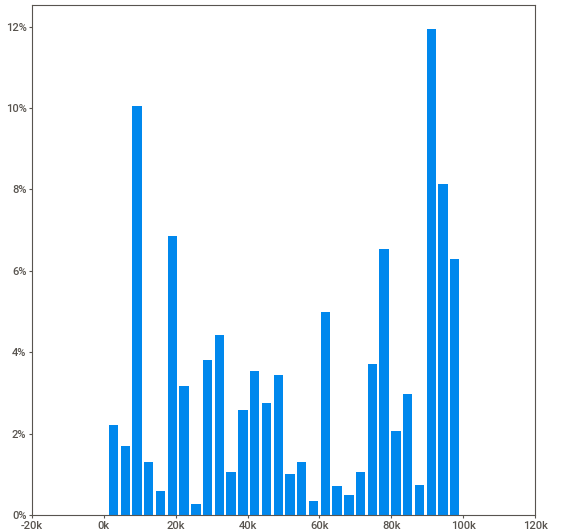
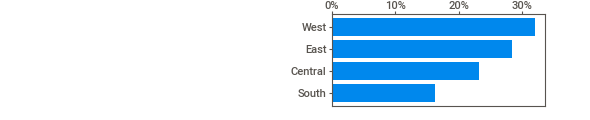
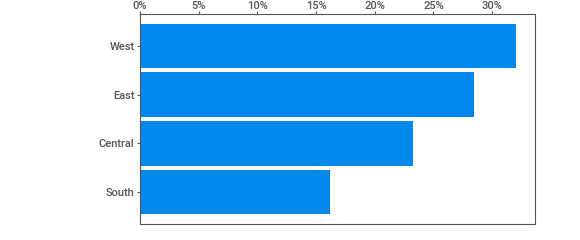
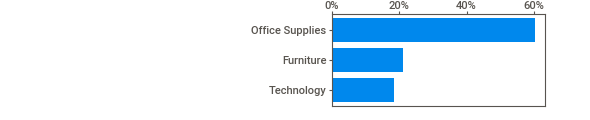
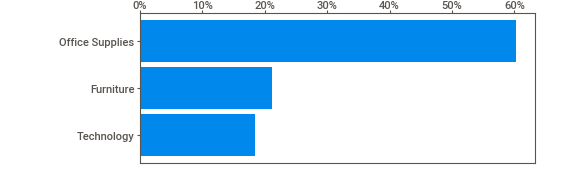
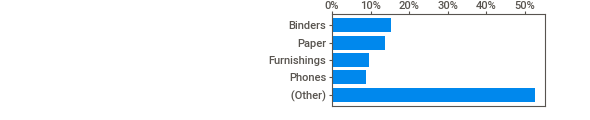
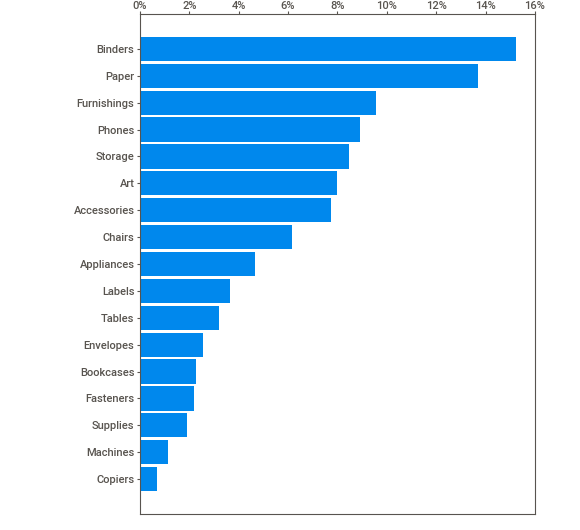
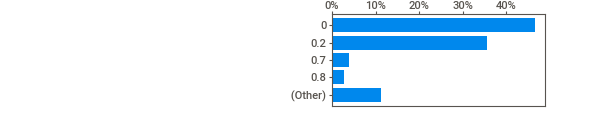
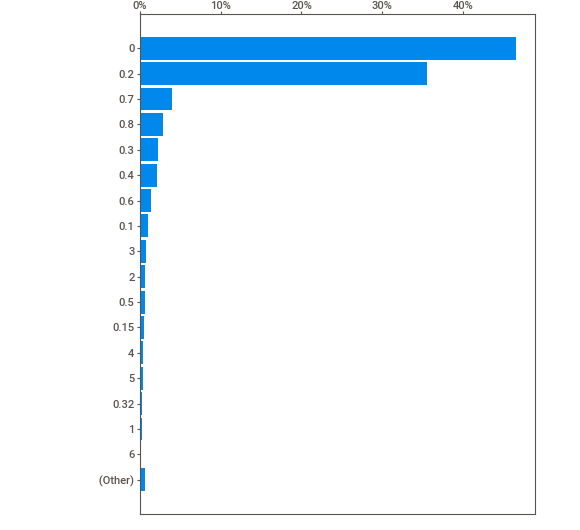
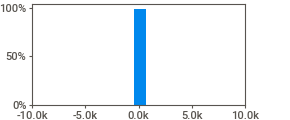
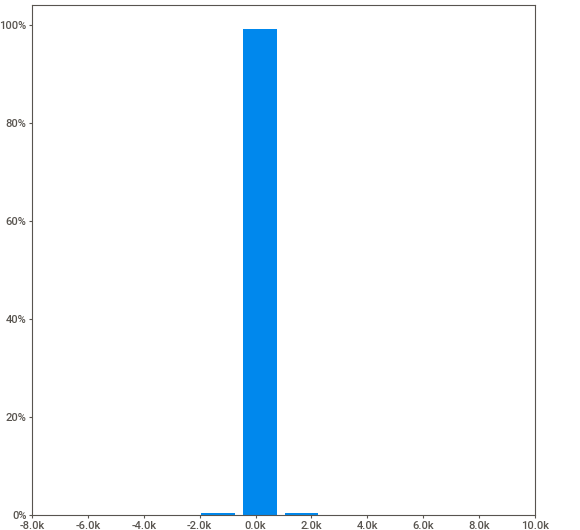
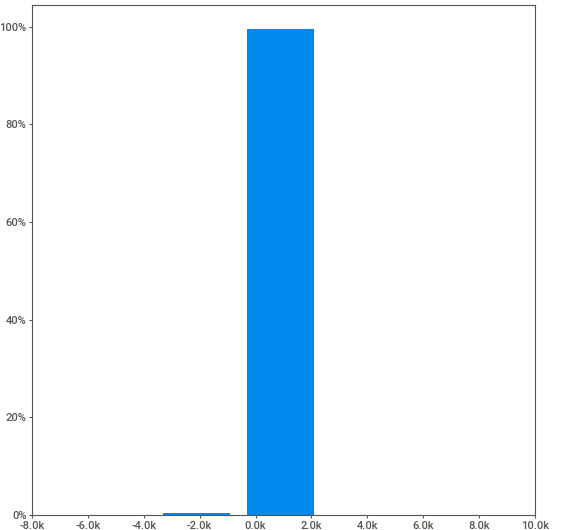
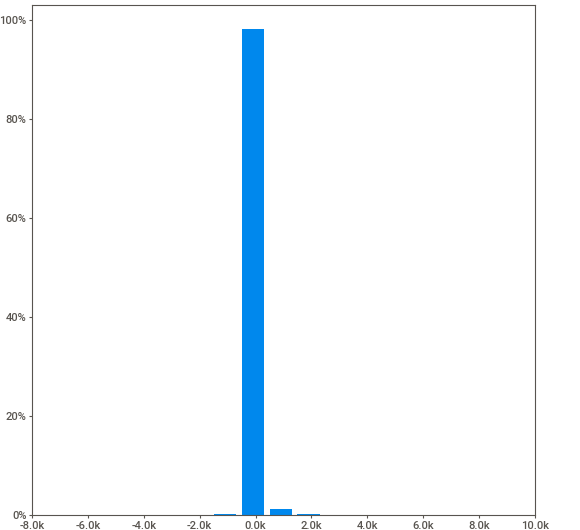
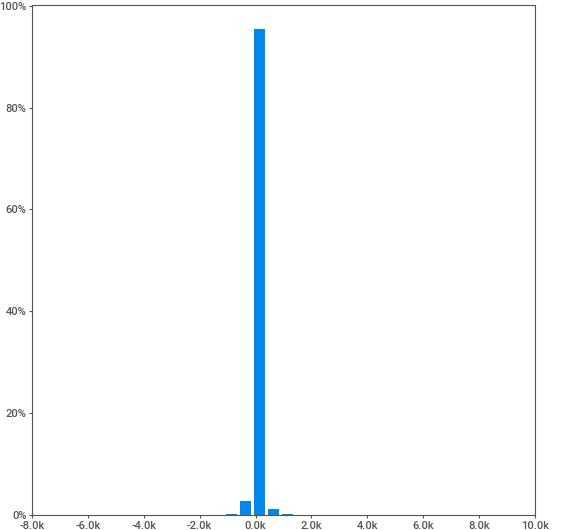
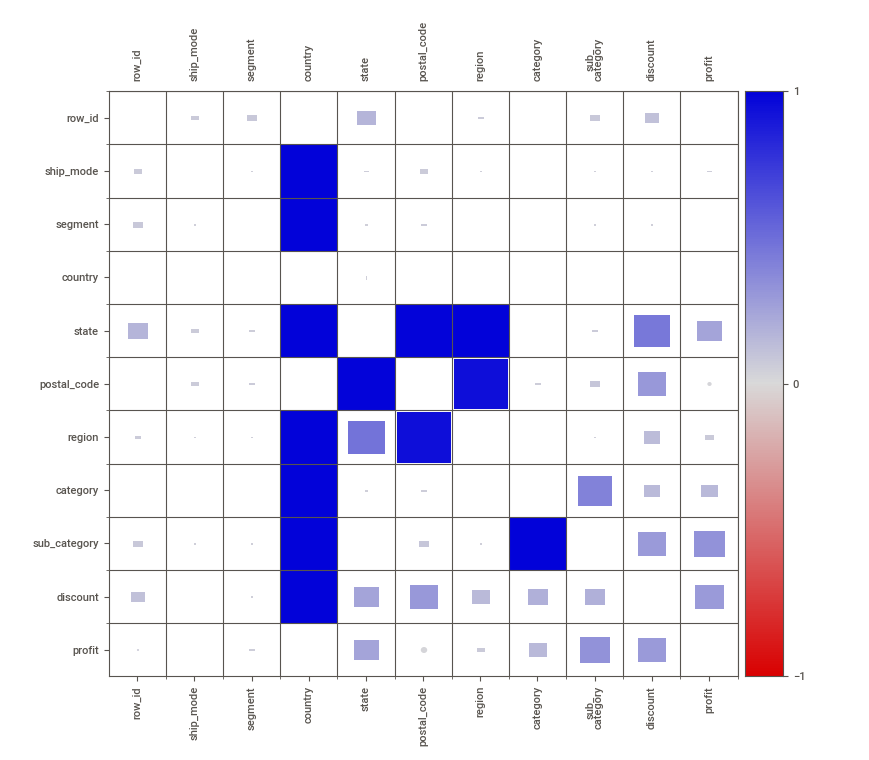
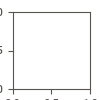

In [0]:
# Display the full report inside Databricks.
# Give the report time to render before moving to the next cell.

store_basic_report.show_notebook()

### Read the report

Use the report to identify questions rather than conclusions.

Focus on:

1. The distributions of sales, profit and discount.
2. The balance across segment, region and category.
3. The number of unique values in identifier fields.
4. Missing values or unusual values.
5. One relationship that should be checked with pandas.

## Lab chunk 3: create profitability flags

### Task

Create two simple indicators:

- `is_profitable`: 1 when profit is greater than zero, otherwise 0
- `is_loss`: 1 when profit is below zero, otherwise 0

These are teaching features. They make rates easy to calculate with `.mean()`.

In [0]:
# Your turn.
# Hint 1: compare the profit column with zero.
# Hint 2: use .astype(int) to turn True and False into 1 and 0.
# Hint 3: check the result with value_counts().


### Coach solution: profitability flags

Both columns are created from the same business measure, but they support different questions.

In [0]:
# Create compact 0 and 1 indicators from the profit column.
# These columns do not change the original profit values.

store["is_profitable"] = (store["profit"] > 0).astype(int)
store["is_loss"] = (store["profit"] < 0).astype(int)

In [0]:
# Check the number of profitable and non-profitable rows.
# This also confirms that the new column contains only 0 and 1.

store["is_profitable"].value_counts()

1    7994
0    2000
Name: is_profitable, dtype: int64

## Lab chunk 4: investigate profitability by category

### Task

Build a category summary with:

- order lines
- total sales
- total profit
- average discount
- loss rate
- profit margin

Sort the result by loss rate from highest to lowest.

In [0]:
# Your turn.
# Hint 1: group by category.
# Hint 2: count order_id for order lines.
# Hint 3: average is_loss to calculate the loss rate.
# Hint 4: calculate profit margin after the groupby.


### Coach solution: category summary

This table converts a broad Sweetviz observation into an exact business comparison.

In [0]:
# Prepare a clean copy for the category summary.
# This protects the main store DataFrame from being changed.

category_data = store.copy()

In [0]:
# Convert the measures used in the calculation to numeric values.
# Any value that cannot be converted, such as text from a malformed row,
# becomes a missing value instead of causing the aggregation to fail.

numeric_columns = ["sales", "profit", "discount"]

category_data[numeric_columns] = category_data[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

In [0]:
# Remove rows where one of the required measures could not be converted.
# These rows should not be included in numeric totals or averages.

category_data = category_data.dropna(
    subset=["category", "order_id", "sales", "profit", "discount"]
)

In [0]:
# Recreate the loss flag from the cleaned profit column.
# A value of 1 represents a loss and 0 represents a profit.

category_data["is_loss"] = (
    category_data["profit"] < 0
).astype(int)

In [0]:
# Calculate the main measures for each product category.
# The mean of the 0 and 1 is_loss field gives the proportion of loss-making rows.

category_summary = category_data.groupby(
    "category",
    as_index=False
).agg(
    order_lines=("order_id", "count"),
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    average_discount=("discount", "mean"),
    loss_rate=("is_loss", "mean")
)

In [0]:
# Display the completed category summary.

category_summary

,category,order_lines,total_sales,total_profit,average_discount,loss_rate
0,Furniture,2074,733046.8613,16980.7712,0.174392,0.338959
1,Office Supplies,5781,703502.9280,120489.8864,0.155561,0.144266
2,Technology,1839,835900.0670,145387.0966,0.132246,0.147363


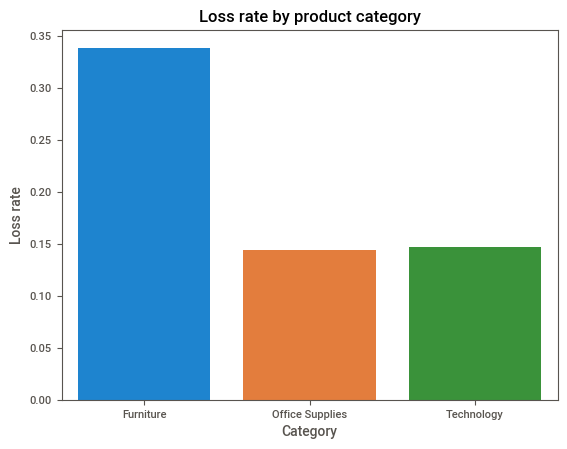

In [0]:
# A bar chart is suitable because there are only three categories.
# The table remains the source of the exact values.

sns.barplot(data=category_summary, x="category", y="loss_rate")
plt.title("Loss rate by product category")
plt.xlabel("Category")
plt.ylabel("Loss rate")
plt.show()

### Coach interpretation

A high loss rate is a signal for follow up, not a complete answer.

Before making a recommendation, check:

- how many order lines sit behind the rate
- whether average discount is also high
- whether the pattern is concentrated in a sub-category
- whether the category still contributes useful total sales and profit

## Lab chunk 5: build a target-focused Superstore report

### Task

Use `is_profitable` as the target in a second Sweetviz report.

This changes the question from "What is in the dataset?" to "Which features appear related to profitability?"

In [0]:
# Your turn.
# Hint 1: use store as the source DataFrame.
# Hint 2: set target_feat="is_profitable".
# Hint 3: display the report in a separate cell.


### Coach solution: profitability target report

The target is already a clean 0 and 1 column, so no further preparation is needed.

In [0]:
# Build the target-focused Superstore report.
# Sweetviz will compare the other features with is_profitable.

store_target_report = sv.analyze(store, target_feat="is_profitable")

                                             |          | [  0%]   00:00 -> (? left)


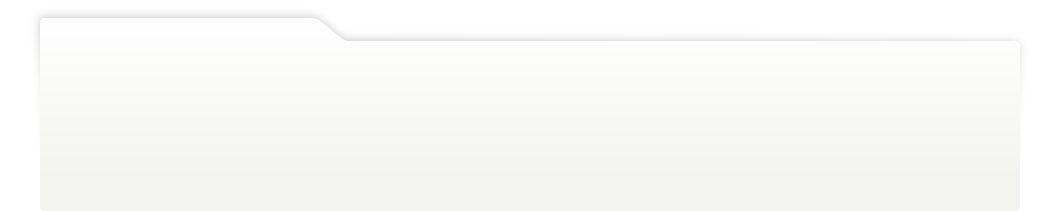
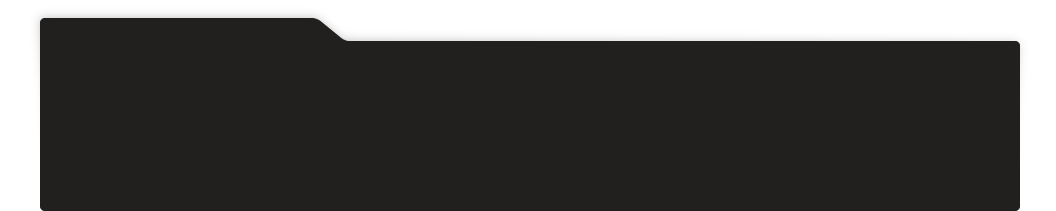
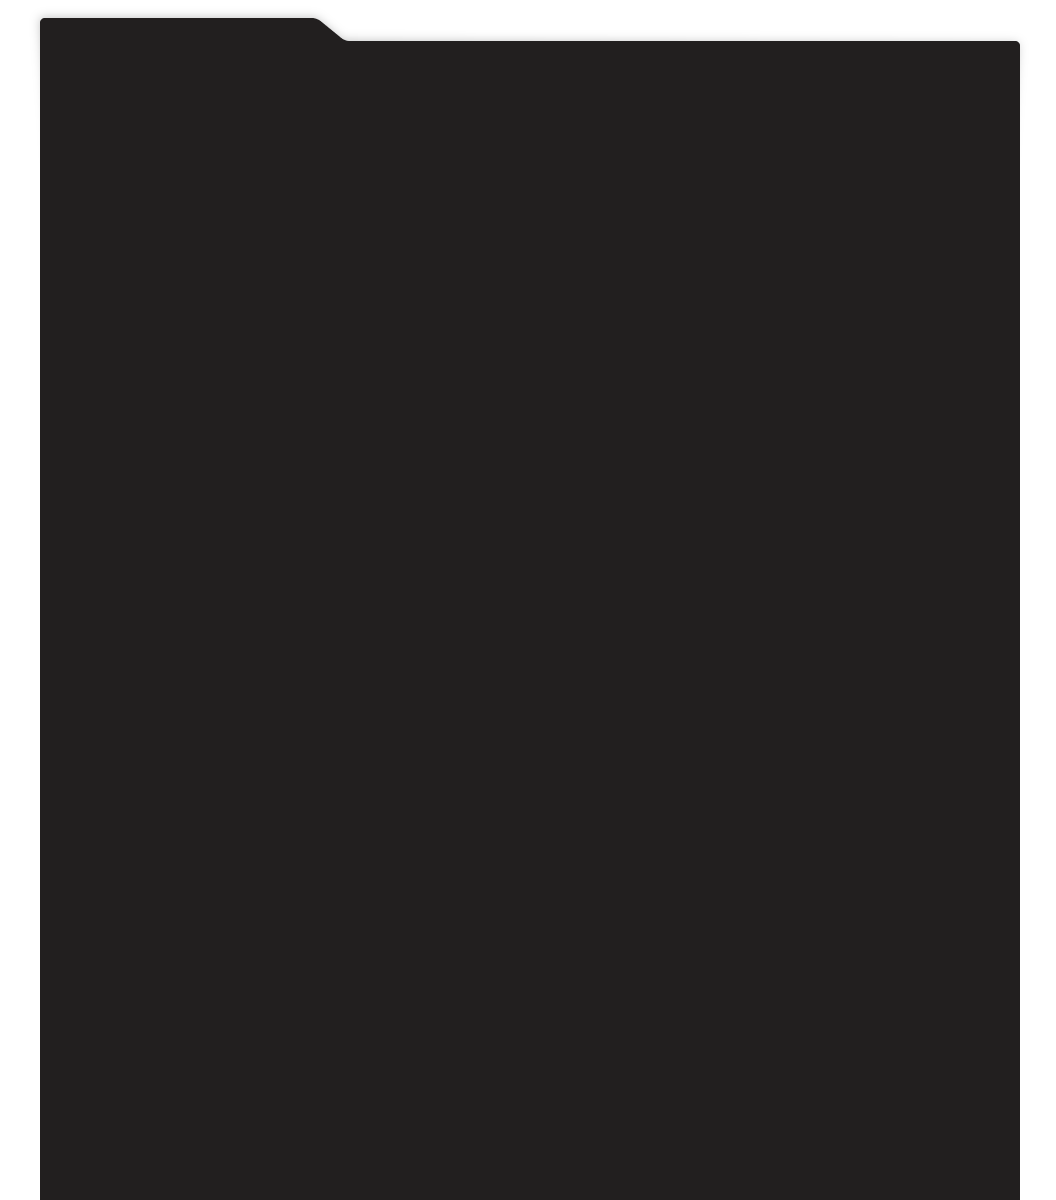
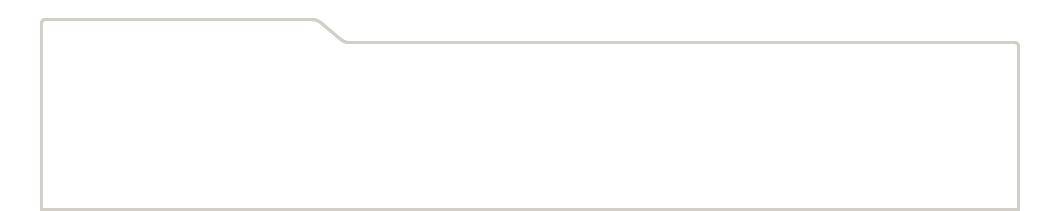
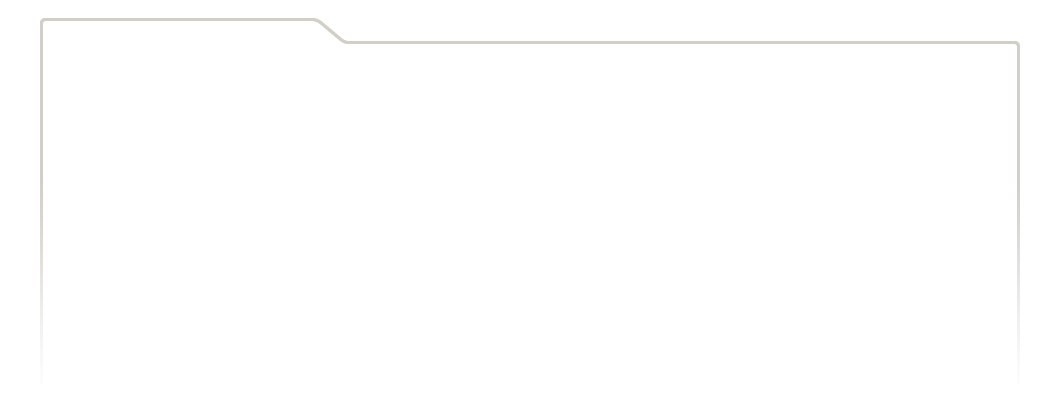
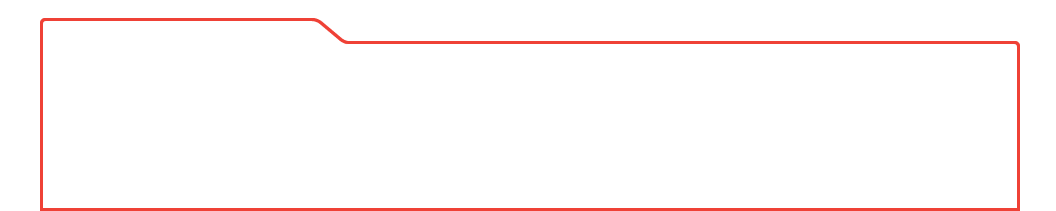
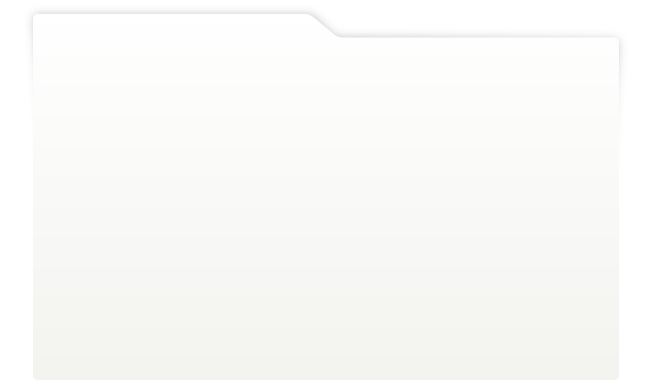
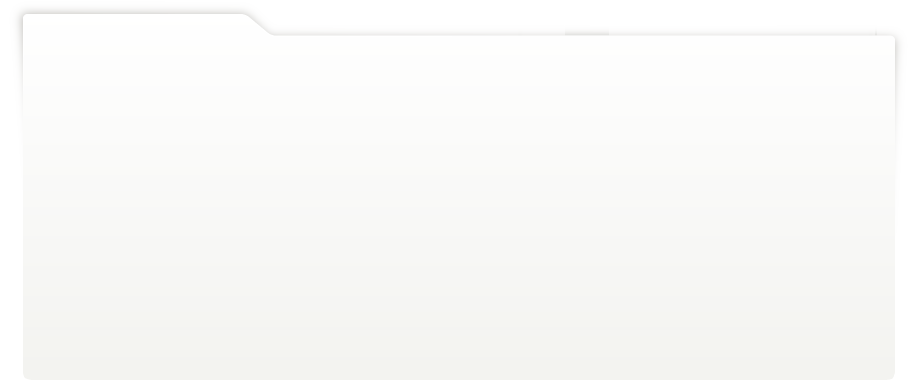
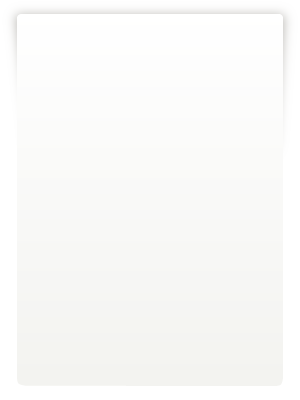
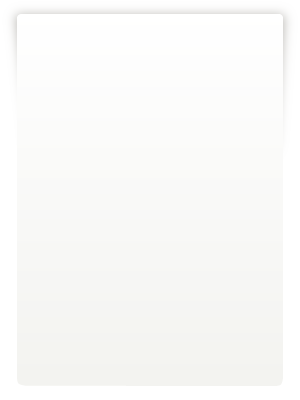
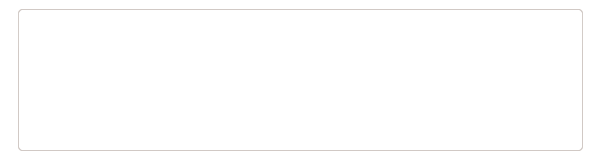
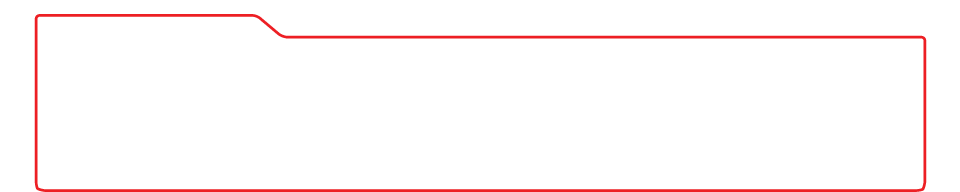
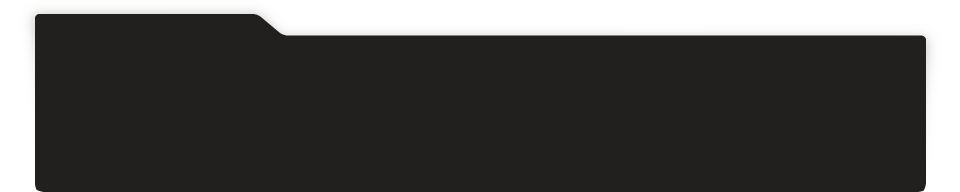
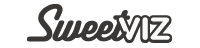
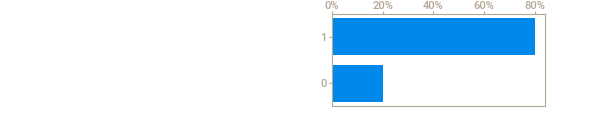
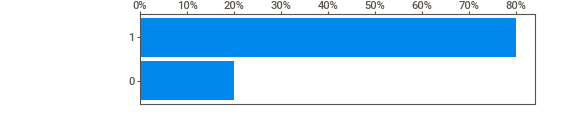
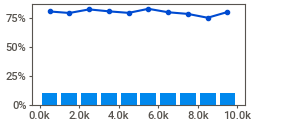
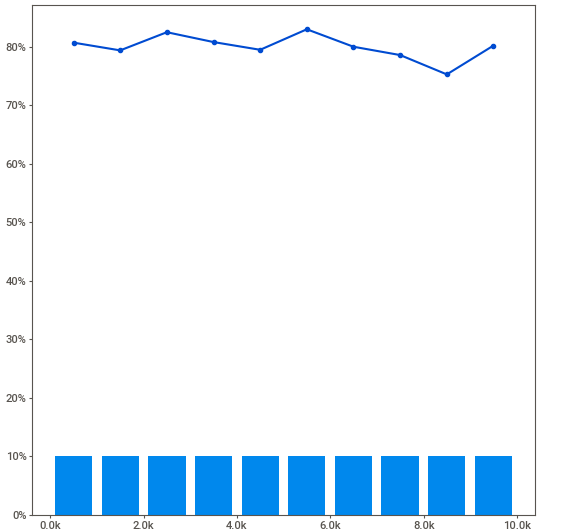
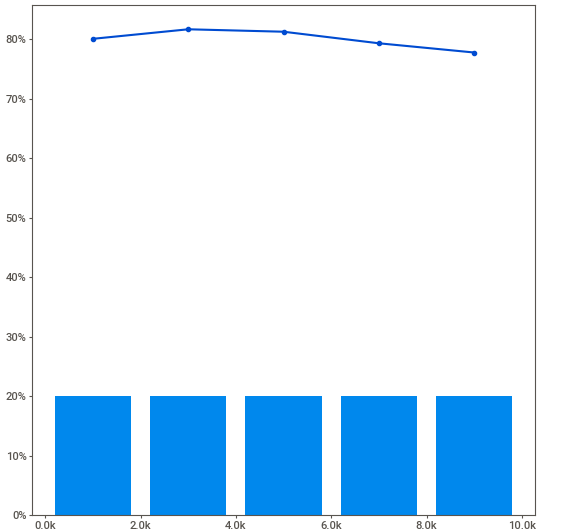
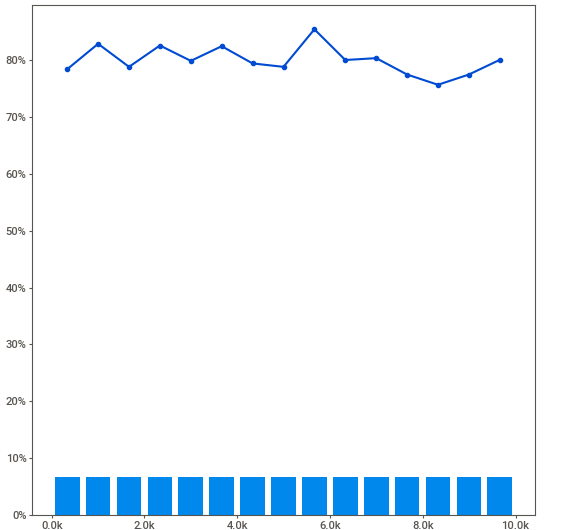
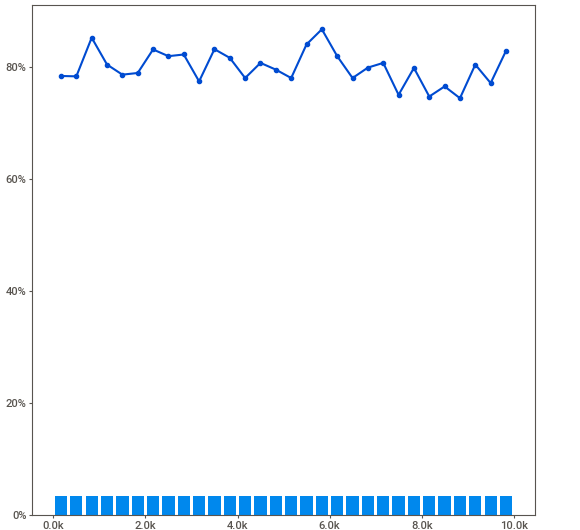
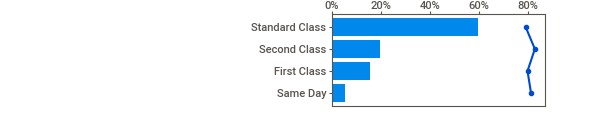
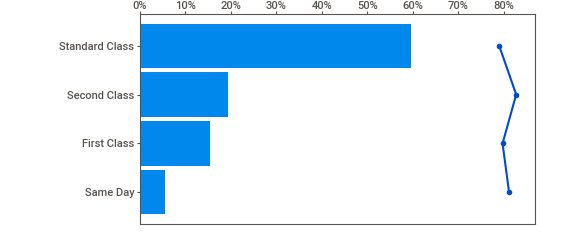
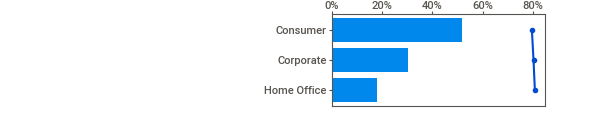
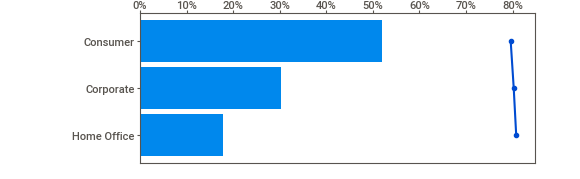
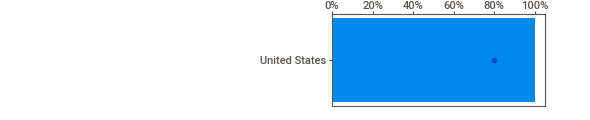
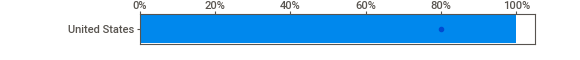
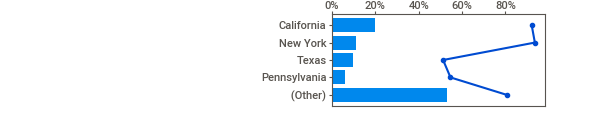
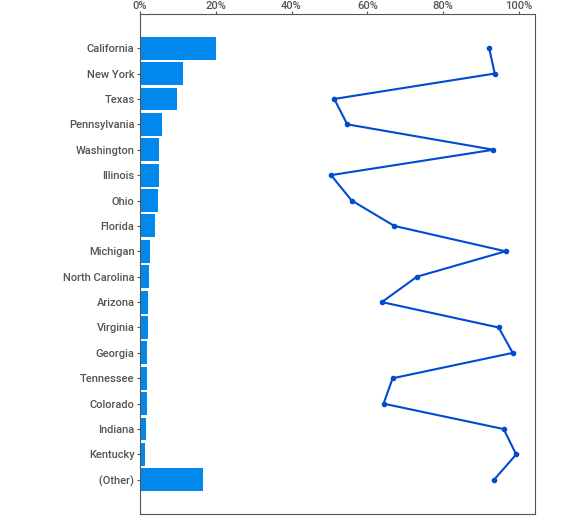
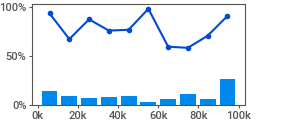
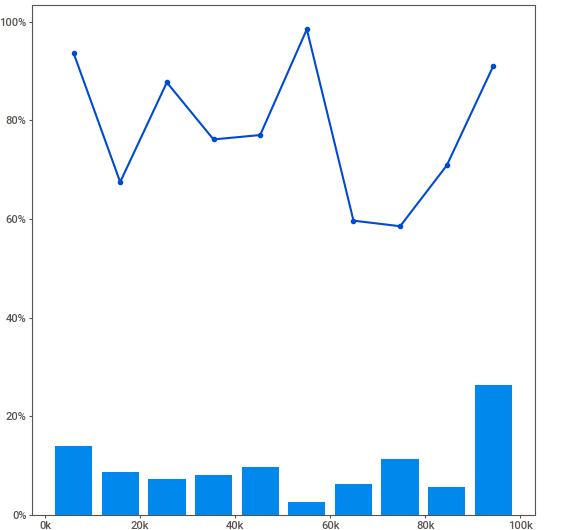
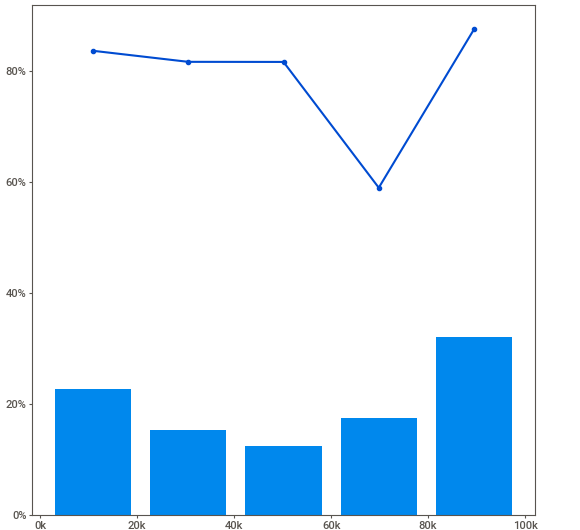
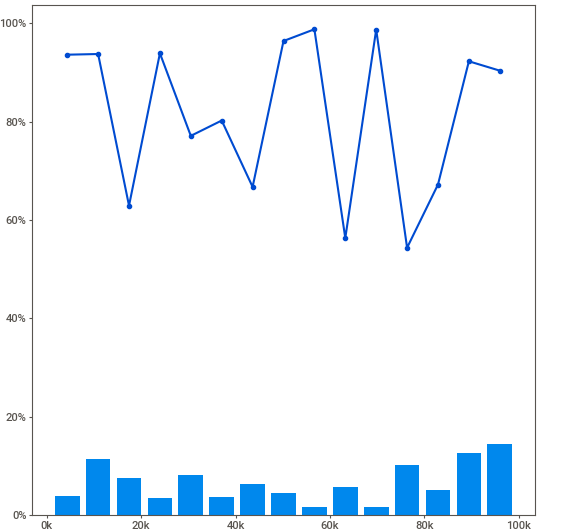
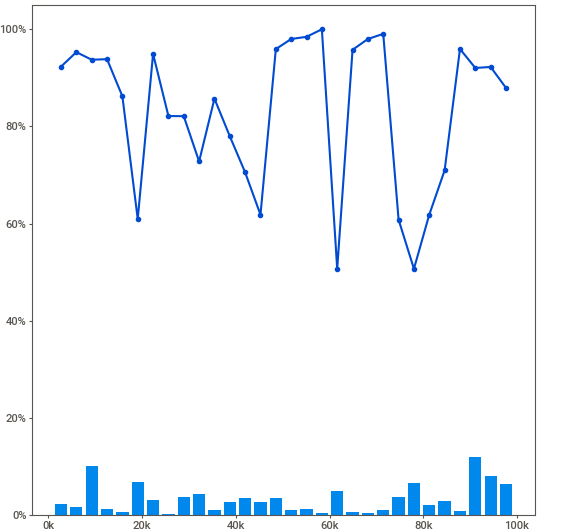
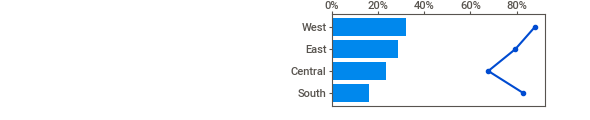
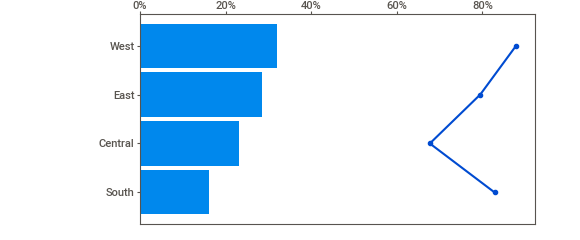
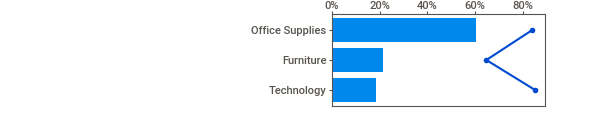
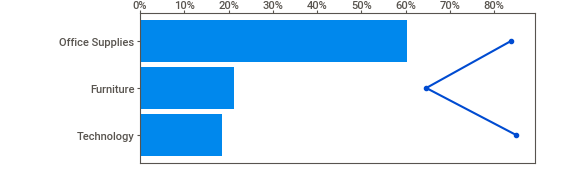
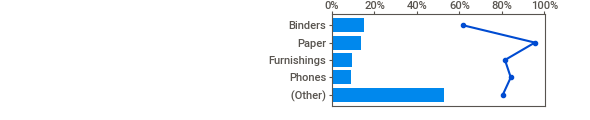
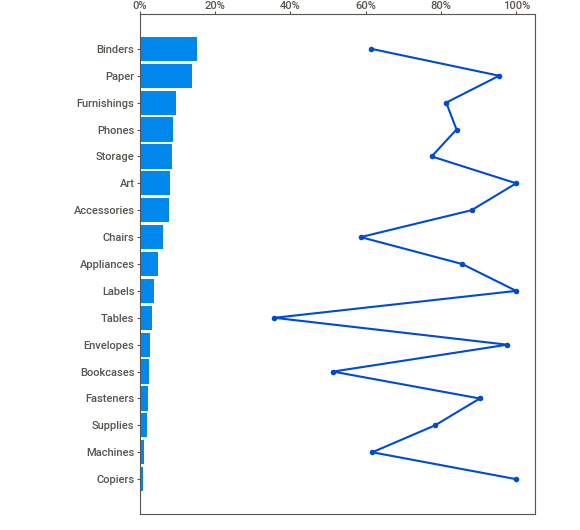
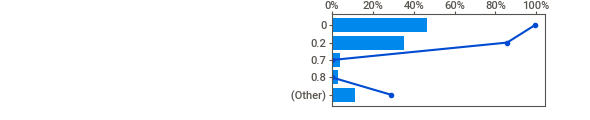
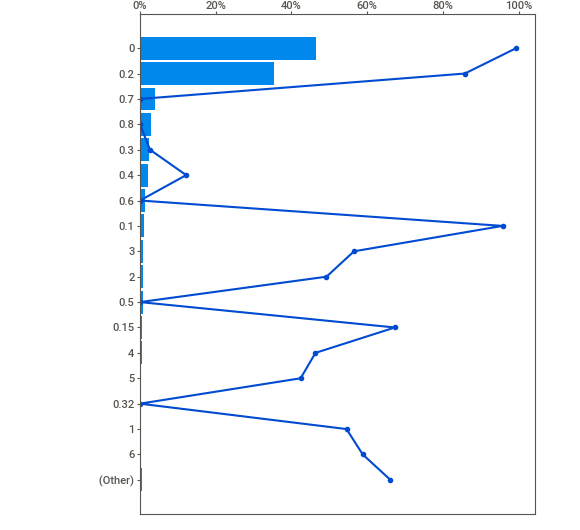
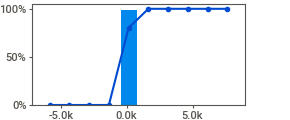
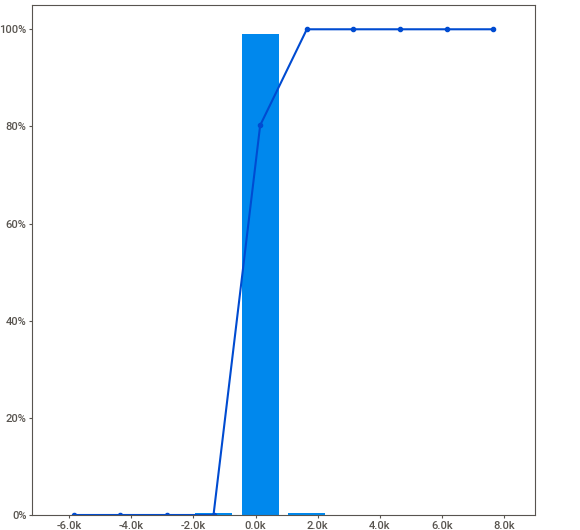
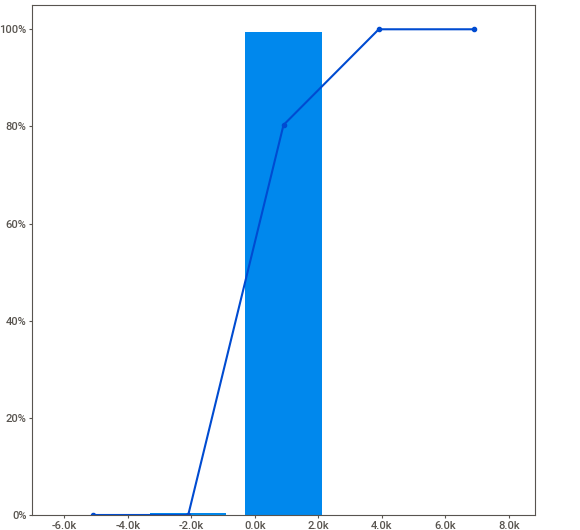
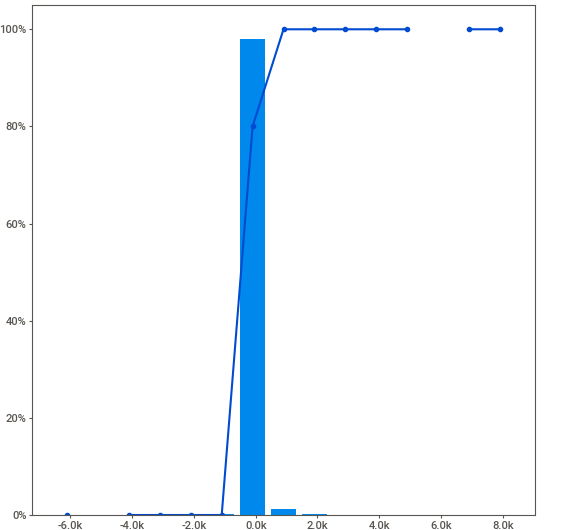
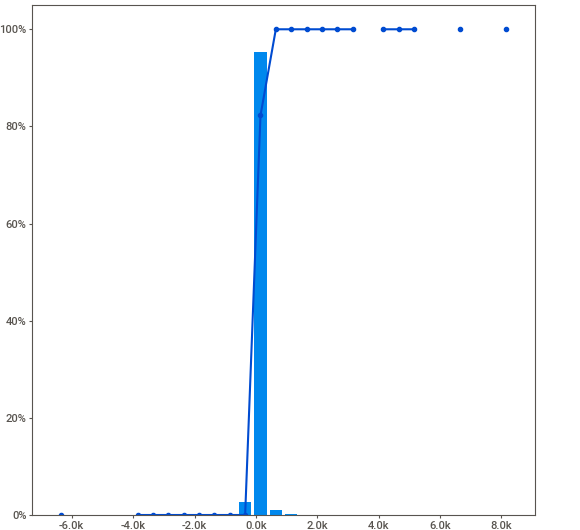
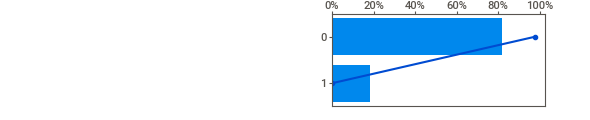
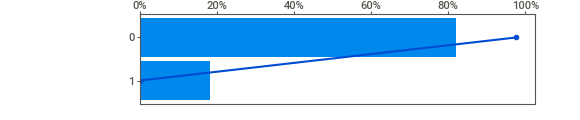
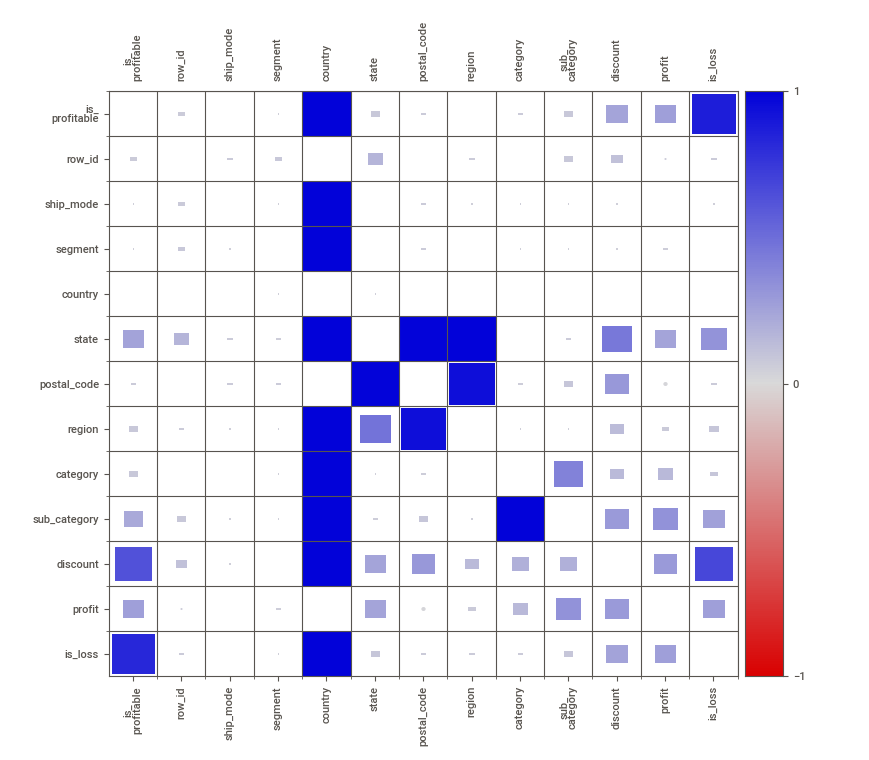
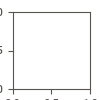

In [0]:
# Display the target report inside Databricks.
# Compare it with the earlier general Superstore report.

store_target_report.show_notebook()

### Read the target report

Focus on:

1. Whether discount appears related to profitability.
2. Whether category or sub-category stands out.
3. Whether any result is driven by an uneven group size.
4. Which finding should be tested with a grouped pandas table.

Sweetviz shows associations. It does not prove that one feature caused another.

## Lab chunk 6: investigate discount groups

### Task

Create five readable discount groups, then compare their loss rates and profit margins.

Use these groups:

- Full Retail: 0 discount
- Welcome Campaign: over 0 up to 20 percent
- Seasonal Clearance: over 20 up to 45 percent
- Mid Incentive Campaign: over 45 up to 60 percent
- Late Season Campaign: over 60 percent

In [0]:
# Your turn.
# Hint 1: use pd.cut() on the discount column.
# Hint 2: provide five bin labels.
# Hint 3: group by the new discount_campaign field.
# Hint 4: calculate loss rate and profit margin.


### Coach solution: create discount groups

The groups turn a continuous discount field into categories that are easier to compare in a business discussion.

In [0]:
# Reuse the cleaned data prepared earlier for the category analysis.
# In category_data, sales, profit and discount are already numeric,
# and rows with malformed values have already been removed.

campaign_data = category_data.copy()

# Create the five campaign groups from the cleaned discount values.
# include_lowest=True ensures that a zero discount is included in Full Retail.

campaign_data["discount_campaign"] = pd.cut(
    campaign_data["discount"],
    bins=[-0.001, 0, 0.20, 0.45, 0.60, 1.00],
    labels=["Full Retail", "Welcome Campaign", "Seasonal Clearance", "Mid Incentive Campaign", "Late Season Campaign"],
    include_lowest=True
)


In [0]:
# Check the number of rows in each campaign group.
# Group size is important when comparing rates between campaigns.

campaign_data["discount_campaign"].value_counts(dropna=False)


Full Retail               4657
Welcome Campaign          3693
Late Season Campaign       676
Seasonal Clearance         470
Mid Incentive Campaign     198
Name: discount_campaign, dtype: int64

### Coach solution: compare campaign performance

We now calculate the evidence needed to evaluate the relationship suggested by the target report.

In [0]:
# Summarise sales, profit, discount and losses by campaign group.
# We use campaign_data because its numeric fields were cleaned earlier.
# observed=True omits unused category labels from the result.

discount_summary = campaign_data.groupby(
    "discount_campaign",
    observed=True,
    as_index=False
).agg(
    order_lines=("order_id", "count"),
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    average_discount=("discount", "mean"),
    loss_rate=("is_loss", "mean")
)


In [0]:
# Add aggregate profit margin for each campaign group.
# This is more meaningful than averaging row-level profit margins.

discount_summary["profit_margin"] = discount_summary["total_profit"] / discount_summary["total_sales"]

In [0]:
# Sort the groups from highest loss rate to lowest.
# Read the rate alongside order_lines and total_sales.

discount_summary = discount_summary.sort_values("loss_rate", ascending=False)
discount_summary

,discount_campaign,order_lines,total_sales,total_profit,average_discount,loss_rate,profit_margin
3,Mid Incentive Campaign,198,6.515594e+04,-26054.8277,0.566667,1.000000,-0.399884
4,Late Season Campaign,676,5.673034e+04,-69779.9669,0.742160,1.000000,-1.230029
2,Seasonal Clearance,470,2.395509e+05,-38318.9682,0.348277,0.906383,-0.159962
1,Welcome Campaign,3693,8.382353e+05,99827.4727,0.196751,0.137558,0.119092
0,Full Retail,4657,1.072777e+06,317184.0443,0.000000,0.000000,0.295666


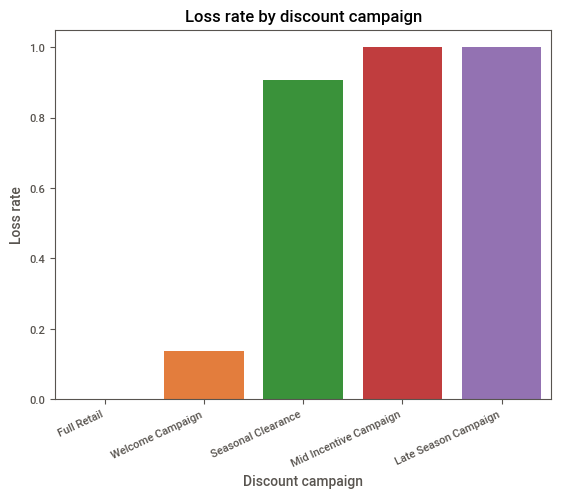

In [0]:
# Plot the loss rate for each discount group.
# Rotation keeps the longer campaign labels readable.

sns.barplot(data=discount_summary, x="discount_campaign", y="loss_rate")
plt.title("Loss rate by discount campaign")
plt.xlabel("Discount campaign")
plt.ylabel("Loss rate")
plt.xticks(rotation=25, ha="right")
plt.show()

### Coach interpretation

If loss rate rises across the deeper discount groups, discounting is a useful area for further investigation.

That pattern still needs context. Deep discounts may be concentrated in particular products, regions or time periods. The grouped result tells us where to look next.

## Lab chunk 7: write the business conclusion

### Task

Write a short conclusion using the category and discount summaries.

Include:

1. One clear finding.
2. One supporting number.
3. One caveat.
4. One recommended follow up.

In [0]:
# Your turn.
# Hint 1: use category_summary.iloc[0] for the highest loss category.
# Hint 2: use discount_summary.iloc[0] for the highest loss discount group.
# Hint 3: keep the conclusion evidence-based and concise.


### Coach solution: extract the headline results

The category table is sorted by loss rate when we select its headline row. The discount table was already sorted in the previous step.


In [0]:
# Select the rows with the highest loss rates.
# Sorting category_summary here ensures that the conclusion uses the correct category.

top_category = category_summary.sort_values(
    "loss_rate",
    ascending=False
).iloc[0]

top_discount_group = discount_summary.iloc[0]


In [0]:
# Write a short conclusion with evidence and a caveat.
# The recommendation stays within what the analysis can support.

print(
    f"The category with the highest loss rate is {top_category['category']} at {top_category['loss_rate']:.1%}. "
    f"The discount group with the highest loss rate is {top_discount_group['discount_campaign']} at {top_discount_group['loss_rate']:.1%}. "
    "This suggests that discounting and category should be investigated together, but the result should be checked at sub-category and product level before any action is taken."
)

The category with the highest loss rate is Furniture at 33.9%. The discount group with the highest loss rate is Mid Incentive Campaign at 100.0%. This suggests that discounting and category should be investigated together, but the result should be checked at sub-category and product level before any action is taken.


<a id="next-steps"></a>
# Section 7: Next steps after automated EDA

After a Sweetviz report, the next step is not to stop at the visual profile.

Use this follow up pattern:

1. Select one useful finding.
2. Build a pandas table to quantify it.
3. Add one chart when it improves communication.
4. Write a plain English conclusion.
5. State the main caveat.

For risk and analytics work, this is what turns an automated report into evidence that a stakeholder can use.

<a id="wrapup"></a>
# Section 8: Wrap up

In this notebook we used Sweetviz as one part of a complete EDA workflow.

The sequence was:

1. Read the data with pandas using the links in `config.py`.
2. Inspect the data types before changing anything.
3. Build a simple Sweetviz report.
4. Add a target only when the analysis had a clear outcome.
5. Validate report findings with pandas tables and charts.
6. Write an evidence-based conclusion.

The key lesson is that Sweetviz gives us a fast starting point. The analyst is still responsible for checking the evidence and explaining what it means.

## Final reflection questions

Use these questions to close the session:

1. What did Sweetviz show faster than manual EDA?
2. Why did we inspect data types before converting any columns?
3. How did the target-focused report differ from the general report?
4. Which Sweetviz finding needed manual validation?
5. What would you check before sharing an automated EDA report with a stakeholder?